In [2]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine


# ============================================================
# 2. DATA FOLDER PATH
# ============================================================

folder_path = r"C:\Users\rishu\Downloads\data\data"

print("Data folder:")
print(folder_path)


# ============================================================
# 3. CHECK FILES
# ============================================================

print("\nFiles available in folder:\n")

for file in os.listdir(folder_path):
    print(file)


# ============================================================
# 4. CSV FILES
# ============================================================

csv_files = [
    file for file in os.listdir(folder_path)
    if file.lower().endswith(".csv")
]

print("\nTotal CSV files:", len(csv_files))

for file in csv_files:
    file_path = os.path.join(folder_path, file)
    size_gb = os.path.getsize(file_path) / (1024**3)
    
    print(f"{file:<30} {size_gb:.2f} GB")


# ============================================================
# 5. LOAD ALL DATASETS
# ============================================================

print("\nLoading datasets...\n")


begin_inventory = pd.read_csv(
    os.path.join(folder_path, "begin_inventory.csv")
)

print("begin_inventory loaded:", begin_inventory.shape)


end_inventory = pd.read_csv(
    os.path.join(folder_path, "end_inventory.csv")
)

print("end_inventory loaded:", end_inventory.shape)


purchases = pd.read_csv(
    os.path.join(folder_path, "purchases.csv")
)

print("purchases loaded:", purchases.shape)


purchase_prices = pd.read_csv(
    os.path.join(folder_path, "purchase_prices.csv")
)

print("purchase_prices loaded:", purchase_prices.shape)


vendor_invoice = pd.read_csv(
    os.path.join(folder_path, "vendor_invoice.csv")
)

print("vendor_invoice loaded:", vendor_invoice.shape)



purchases_prices = purchase_prices



sales = pd.read_csv(
    os.path.join(folder_path, "sales.csv"),
    low_memory=False
)

print("sales loaded:", sales.shape)


# ============================================================
# 7. FINAL DATASET SUMMARY
# ============================================================

print("\n" + "="*70)
print("DATASET SUMMARY")
print("="*70)

datasets = {
    "begin_inventory": begin_inventory,
    "end_inventory": end_inventory,
    "purchases": purchases,
    "purchase_prices": purchase_prices,
    "sales": sales,
    "vendor_invoice": vendor_invoice
}

for name, df in datasets.items():
    print(
        f"{name:<20} "
        f"Rows: {df.shape[0]:>10,} | "
        f"Columns: {df.shape[1]:>3}"
    )

Data folder:
C:\Users\rishu\Downloads\data\data

Files available in folder:

.ipynb_checkpoints
begin_inventory.csv
end_inventory.csv
final_analysis
purchases.csv
purchase_prices.csv
sales.csv
vendor_invoice.csv

Total CSV files: 6
begin_inventory.csv            0.02 GB
end_inventory.csv              0.02 GB
purchases.csv                  0.34 GB
purchase_prices.csv            0.00 GB
sales.csv                      1.49 GB
vendor_invoice.csv             0.00 GB

Loading datasets...

begin_inventory loaded: (206529, 9)
end_inventory loaded: (224489, 9)
purchases loaded: (2372474, 16)
purchase_prices loaded: (12261, 9)
vendor_invoice loaded: (5543, 10)
sales loaded: (12825363, 14)

DATASET SUMMARY
begin_inventory      Rows:    206,529 | Columns:   9
end_inventory        Rows:    224,489 | Columns:   9
purchases            Rows:  2,372,474 | Columns:  16
purchase_prices      Rows:     12,261 | Columns:   9
sales                Rows: 12,825,363 | Columns:  14
vendor_invoice       Rows:    

In [3]:
print("Begin Inventory:", begin_inventory.shape)
print("End Inventory:", end_inventory.shape)
print("Purchases:", purchases.shape)
print("Purchase Prices:", purchase_prices.shape)
print("Sales:", sales.shape)
print("Vendor Invoice:", vendor_invoice.shape)

Begin Inventory: (206529, 9)
End Inventory: (224489, 9)
Purchases: (2372474, 16)
Purchase Prices: (12261, 9)
Sales: (12825363, 14)
Vendor Invoice: (5543, 10)


In [4]:
print("\nSales Columns:")
print(sales.columns.tolist())

print("\nPurchases Columns:")
print(purchases.columns.tolist())

print("\nPurchase Prices Columns:")
print(purchase_prices.columns.tolist())

print("\nVendor Invoice Columns:")
print(vendor_invoice.columns.tolist())


Sales Columns:
['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'SalesQuantity', 'SalesDollars', 'SalesPrice', 'SalesDate', 'Volume', 'Classification', 'ExciseTax', 'VendorNo', 'VendorName']

Purchases Columns:
['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'VendorNumber', 'VendorName', 'PONumber', 'PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification']

Purchase Prices Columns:
['Brand', 'Description', 'Price', 'Size', 'Volume', 'Classification', 'PurchasePrice', 'VendorNumber', 'VendorName']

Vendor Invoice Columns:
['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate', 'PayDate', 'Quantity', 'Dollars', 'Freight', 'Approval']


In [5]:
# Compatibility variable
purchases_prices = purchase_prices

In [6]:
sales = pd.read_csv(
    os.path.join(folder_path, "sales.csv"),
    low_memory=False
)

In [15]:
# ============================================================
# EXPLORATORY DATA ANALYSIS
# ============================================================

datasets = {
    "begin_inventory": begin_inventory,
    "end_inventory": end_inventory,
    "purchase_prices": purchase_prices,
    "purchases": purchases,
    "sales": sales,
    "vendor_invoice": vendor_invoice
}

for name, df in datasets.items():
    
    print("\n" + "=" * 70)
    print(f"TOP 10 RECORDS OF {name.upper()}")
    print("=" * 70)
    
    display(df.head(10))


TOP 10 RECORDS OF BEGIN_INVENTORY


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01
5,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,18,14.99,2024-01-01
6,1_HARDERSFIELD_77,1,HARDERSFIELD,77,Three Olives Espresso Vodka,750mL,7,14.99,2024-01-01
7,1_HARDERSFIELD_79,1,HARDERSFIELD,79,Three Olives Loopy Vodka,750mL,2,14.99,2024-01-01
8,1_HARDERSFIELD_115,1,HARDERSFIELD,115,Belvedere Vodka,Liter,5,27.99,2024-01-01
9,1_HARDERSFIELD_120,1,HARDERSFIELD,120,Tarantula Azul Tequila Gift,750mL,11,13.99,2024-01-01



TOP 10 RECORDS OF END_INVENTORY


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31
5,1_HARDERSFIELD_77,1,HARDERSFIELD,77,Three Olives Espresso Vodka,750mL,18,14.99,2024-12-31
6,1_HARDERSFIELD_79,1,HARDERSFIELD,79,Three Olives Loopy Vodka,750mL,7,14.99,2024-12-31
7,1_HARDERSFIELD_115,1,HARDERSFIELD,115,Belvedere Vodka,Liter,35,27.99,2024-12-31
8,1_HARDERSFIELD_126,1,HARDERSFIELD,126,Grey Goose Vodka,Liter,36,29.99,2024-12-31
9,1_HARDERSFIELD_159,1,HARDERSFIELD,159,Glenmorangie Original VAP,750mL + 2/,8,34.99,2024-12-31



TOP 10 RECORDS OF PURCHASE_PRICES


...

,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1
5,5_SUTTON_3348,5,3348,Bombay Sapphire Gin,1.75L,480,BACARDI USA INC,8106,2023-12-20,2024-01-02,2024-01-12,2024-02-05,22.38,6,134.28,1
6,1_HARDERSFIELD_8358,1,8358,Bacardi 151 Proof,750mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,14.49,12,173.88,1
7,30_CULCHETH_4903,30,4903,Bacardi Superior Rum,200mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,2.87,48,137.76,1
8,34_PITMERDEN_3782,34,3782,Grey Goose Le Citron Vodka,750mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-02,2024-01-12,2024-02-05,18.89,5,94.45,1
9,1_HARDERSFIELD_4233,1,4233,Castillo Silver Label Rum,1.75L,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,7.87,23,181.01,1



TOP 10 RECORDS OF SALES


,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-01,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
1,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,2,32.98,16.49,2024-01-02,750.0,1,1.57,12546,JIM BEAM BRANDS COMPANY
2,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,16.49,16.49,2024-01-03,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
3,1_HARDERSFIELD_1004,1,1004,Jim Beam w/2 Rocks Glasses,750mL,1,14.49,14.49,2024-01-08,750.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
4,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,2,69.98,34.99,2024-01-09,375.0,1,0.79,12546,JIM BEAM BRANDS COMPANY
5,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,1,34.99,34.99,2024-01-15,375.0,1,0.39,12546,JIM BEAM BRANDS COMPANY
6,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,1,34.99,34.99,2024-01-22,375.0,1,0.39,12546,JIM BEAM BRANDS COMPANY
7,1_HARDERSFIELD_1005,1,1005,Maker's Mark Combo Pack,375mL 2 Pk,1,34.99,34.99,2024-01-30,375.0,1,0.39,12546,JIM BEAM BRANDS COMPANY
8,1_HARDERSFIELD_10058,1,10058,F Coppola Dmd Ivry Cab Svgn,750mL,4,59.96,14.99,2024-01-05,750.0,2,0.45,2000,SOUTHERN WINE & SPIRITS NE
9,1_HARDERSFIELD_10058,1,10058,F Coppola Dmd Ivry Cab Svgn,750mL,1,14.99,14.99,2024-01-06,750.0,2,0.11,2000,SOUTHERN WINE & SPIRITS NE



TOP 10 RECORDS OF VENDOR_INVOICE


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,NaN
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,NaN
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,NaN
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,NaN
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,NaN
5,2396,BLACK PRINCE DISTILLERY INC,2024-01-08,8191,2023-12-25,2024-02-06,23,234.83,2.30,NaN
6,1128,BROWN-FORMAN CORP,2024-01-09,8150,2023-12-23,2024-02-19,4684,65403.57,1808.77,NaN
7,1189,BULLY BOY DISTILLERS,2024-01-09,8171,2023-12-24,2024-02-04,6,132.30,5.29,NaN
8,1273,CALEDONIA SPIRITS INC,2024-01-06,8172,2023-12-24,2024-02-15,5,146.80,15.53,NaN
9,11567,CAMPARI AMERICA,2024-01-06,8151,2023-12-23,2024-02-20,1321,12039.71,398.71,NaN


In [16]:
purchases[purchases['VendorNumber'] == 4466].head(20)

,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
8091,38_GOULCREST_5215,38,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-07,2024-01-19,2024-02-26,9.41,6,56.46,1
8092,59_CLAETHORPES_5215,59,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-05,2024-01-19,2024-02-26,9.41,6,56.46,1
8093,67_EANVERNESS_5215,67,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-08,2024-01-19,2024-02-26,9.41,6,56.46,1
8094,48_NORFOLK_5255,48,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-05,2024-01-19,2024-02-26,9.35,6,56.10,1
8095,74_PAENTMARWY_5215,74,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-05,2024-01-19,2024-02-26,9.41,6,56.46,1
8096,23_ARBINGTON_5255,23,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-05,2024-01-19,2024-02-26,9.35,6,56.10,1
8097,14_BROMWICH_5215,14,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8207,2023-12-27,2024-01-06,2024-01-19,2024-02-26,9.41,6,56.46,1


In [17]:
vendor_invoice[vendor_invoice['VendorNumber'] == 4466].head(20)

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,NaN
90,4466,AMERICAN VINTAGE BEVERAGE,2024-01-19,8207,2023-12-27,2024-02-26,335,3142.33,16.97,NaN
189,4466,AMERICAN VINTAGE BEVERAGE,2024-01-18,8307,2024-01-03,2024-02-18,41,383.35,1.99,NaN
284,4466,AMERICAN VINTAGE BEVERAGE,2024-01-27,8469,2024-01-14,2024-03-11,72,673.20,3.30,NaN
380,4466,AMERICAN VINTAGE BEVERAGE,2024-02-04,8532,2024-01-19,2024-03-15,79,740.21,3.48,NaN
486,4466,AMERICAN VINTAGE BEVERAGE,2024-02-09,8604,2024-01-24,2024-03-15,347,3261.37,17.61,NaN
586,4466,AMERICAN VINTAGE BEVERAGE,2024-02-17,8793,2024-02-05,2024-04-02,72,675.36,3.17,NaN
691,4466,AMERICAN VINTAGE BEVERAGE,2024-03-01,8892,2024-02-12,2024-03-28,117,1096.05,5.15,NaN
798,4466,AMERICAN VINTAGE BEVERAGE,2024-03-07,8995,2024-02-19,2024-04-02,129,1209.27,5.44,NaN
899,4466,AMERICAN VINTAGE BEVERAGE,2024-03-12,9033,2024-02-22,2024-04-16,147,1377.87,6.61,NaN


In [18]:
sales[sales['VendorNo'] == 4466].head(20)

,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
13370,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-09,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13371,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-12,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13372,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-15,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13373,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-21,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13374,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-23,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13375,1_HARDERSFIELD_5215,1,5215,TGI Fridays Long Island Iced,1.75L,1,12.99,12.99,2024-01-31,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13472,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-01-02,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13473,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-01-07,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13474,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,1,12.99,12.99,2024-01-14,1750.0,1,1.84,4466,AMERICAN VINTAGE BEVERAGE
13475,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,2,25.98,12.99,2024-01-15,1750.0,1,3.67,4466,AMERICAN VINTAGE BEVERAGE


In [19]:
purchase_summary = (
    purchases
    .groupby(['Brand', 'PurchasePrice'], as_index=False)
    .agg(
        TotalQuantity=('Quantity', 'sum'),
        TotalPurchaseDollars=('Dollars', 'sum')
    )
    .sort_values('TotalPurchaseDollars', ascending=False)
)

display(purchase_summary.head(20))

,Brand,PurchasePrice,TotalQuantity,TotalPurchaseDollars
571,1233,26.27,145080,3811251.60
1629,3405,23.19,164038,3804041.22
3159,8068,18.24,187407,3418303.68
2122,4261,16.17,201682,3261197.94
1710,3545,21.89,138109,3023206.01
1911,3858,17.77,138809,2466635.93
1139,2589,30.76,70783,2177285.08
1464,3102,12.94,161386,2088334.84
1678,3489,20.73,91835,1903739.55
631,1376,16.29,108866,1773427.14


In [20]:
print("Unique Purchase Orders:",
      vendor_invoice['PONumber'].nunique())

print("Vendor Invoice Shape:",
      vendor_invoice.shape)

print("\nPurchases Columns:")
print(purchases.columns.tolist())

print("\nVendor Invoice Columns:")
print(vendor_invoice.columns.tolist())

print("\nPurchase Prices Columns:")
print(purchase_prices.columns.tolist())

Unique Purchase Orders: 5543
Vendor Invoice Shape: (5543, 10)

Purchases Columns:
['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'VendorNumber', 'VendorName', 'PONumber', 'PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification']

Vendor Invoice Columns:
['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate', 'PayDate', 'Quantity', 'Dollars', 'Freight', 'Approval']

Purchase Prices Columns:
['Brand', 'Description', 'Price', 'Size', 'Volume', 'Classification', 'PurchasePrice', 'VendorNumber', 'VendorName']


In [21]:
# ============================================================
# VENDOR SALES SUMMARY
# ============================================================

vendor_sales_summary = (
    sales
    .groupby(['VendorNo', 'VendorName'], as_index=False)
    .agg(
        TotalSalesDollars=('SalesDollars', 'sum'),
        TotalSalesQuantity=('SalesQuantity', 'sum'),
        NumberOfSalesTransactions=('InventoryId', 'count')
    )
)

vendor_sales_summary.head(10)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482
2,105,ALTAMAR BRANDS LLC,15748.75,325,267
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32
4,287,APPOLO VINEYARDS LLC,1616.92,108,98
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,1480
6,480,BACARDI USA INC,25014556.89,1457301,539472
7,516,BANFI PRODUCTS CORP,2646325.62,221040,110189
8,653,STATE WINE & SPIRITS,2299075.40,157700,80087
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,211773


In [22]:
# ============================================================
# VENDOR PURCHASE SUMMARY
# ============================================================

vendor_purchase_summary = (
    purchases
    .groupby(['VendorNumber', 'VendorName'], as_index=False)
    .agg(
        TotalPurchaseDollars=('Dollars', 'sum'),
        TotalPurchaseQuantity=('Quantity', 'sum'),
        NumberOfPurchaseTransactions=('PONumber', 'count')
    )
)

vendor_purchase_summary.head(10)

,VendorNumber,VendorName,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,328,13
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07,1,1
2,60,ADAMBA IMPORTS INTL INC,76770.25,4732,626
3,105,ALTAMAR BRANDS LLC,11706.20,332,57
4,200,AMERICAN SPIRITS EXCHANGE,1205.16,132,8
5,287,APPOLO VINEYARDS LLC,2399.70,230,18
6,388,ATLANTIC IMPORTING COMPANY,41116.32,1847,266
7,480,BACARDI USA INC,17624378.72,1427075,91846
8,516,BANFI PRODUCTS CORP,1628866.68,228103,23510
9,653,STATE WINE & SPIRITS,1529682.04,154092,11406


In [23]:
# ============================================================
# MERGE SALES AND PURCHASE SUMMARY
# ============================================================

vendor_sales_summary = vendor_sales_summary.merge(
    vendor_purchase_summary,
    left_on='VendorNo',
    right_on='VendorNumber',
    how='left',
    suffixes=('', '_Purchase')
)

vendor_sales_summary.head(10)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,VendorNumber,VendorName_Purchase,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,2.0,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,328.0,13.0
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,60.0,ADAMBA IMPORTS INTL INC,76770.25,4732.0,626.0
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,105.0,ALTAMAR BRANDS LLC,11706.20,332.0,57.0
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,200.0,AMERICAN SPIRITS EXCHANGE,1205.16,132.0,8.0
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,287.0,APPOLO VINEYARDS LLC,2399.70,230.0,18.0
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,1480,388.0,ATLANTIC IMPORTING COMPANY,41116.32,1847.0,266.0
6,480,BACARDI USA INC,25014556.89,1457301,539472,480.0,BACARDI USA INC,17624378.72,1427075.0,91846.0
7,516,BANFI PRODUCTS CORP,2646325.62,221040,110189,516.0,BANFI PRODUCTS CORP,1628866.68,228103.0,23510.0
8,653,STATE WINE & SPIRITS,2299075.40,157700,80087,653.0,STATE WINE & SPIRITS,1529682.04,154092.0,11406.0
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,211773,660.0,SAZERAC NORTH AMERICA INC.,3537977.55,503931.0,54331.0


In [24]:
#unecessary dublicate columns remove
vendor_sales_summary.drop(
    columns=['VendorNumber', 'VendorName_Purchase'],
    inplace=True,
    errors='ignore'
)

vendor_sales_summary.head()

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,5630.88,328.0,13.0
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,11706.20,332.0,57.0
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,1205.16,132.0,8.0
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,2399.70,230.0,18.0


In [25]:
# ============================================================
# GROSS PROFIT
# ============================================================

vendor_sales_summary['GrossProfit'] = (
    vendor_sales_summary['TotalSalesDollars']
    - vendor_sales_summary['TotalPurchaseDollars']
)

vendor_sales_summary.head()

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,GrossProfit
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,5630.88,328.0,13.0,-4365.30
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0,-9194.03
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,11706.20,332.0,57.0,4042.55
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,1205.16,132.0,8.0,514.81
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,2399.70,230.0,18.0,-782.78


In [26]:
# ============================================================
# PROFIT MARGIN %
# ============================================================

vendor_sales_summary['ProfitMargin'] = (
    vendor_sales_summary['GrossProfit']
    / vendor_sales_summary['TotalSalesDollars']
) * 100

vendor_sales_summary.head()

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,GrossProfit,ProfitMargin
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,5630.88,328.0,13.0,-4365.30,-344.924857
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0,-9194.03,-13.605422
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,11706.20,332.0,57.0,4042.55,25.669021
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,1205.16,132.0,8.0,514.81,29.931336
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,2399.70,230.0,18.0,-782.78,-48.411795


In [27]:
# ============================================================
# VENDOR INVOICE SUMMARY
# ============================================================

vendor_invoice_summary = (
    vendor_invoice
    .groupby(['VendorNumber', 'VendorName'], as_index=False)
    .agg(
        TotalInvoiceDollars=('Dollars', 'sum'),
        TotalFreight=('Freight', 'sum'),
        TotalInvoiceQuantity=('Quantity', 'sum'),
        TotalPurchaseOrders=('PONumber', 'nunique')
    )
)

vendor_invoice_summary.head()

,VendorNumber,VendorName,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,27.08,328,4
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07,0.48,1,1
2,60,ADAMBA IMPORTS INTL INC,76770.25,367.52,4732,35
3,105,ALTAMAR BRANDS LLC,11706.20,62.39,332,40
4,200,AMERICAN SPIRITS EXCHANGE,1205.16,6.19,132,6


In [28]:
# ============================================================
# MERGE INVOICE INFORMATION
# ============================================================

vendor_sales_summary = vendor_sales_summary.merge(
    vendor_invoice_summary,
    left_on='VendorNo',
    right_on='VendorNumber',
    how='left'
)

vendor_sales_summary.drop(
    columns=['VendorNumber', 'VendorName_y'],
    inplace=True,
    errors='ignore'
)

vendor_sales_summary.head()

,VendorNo,VendorName_x,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,GrossProfit,ProfitMargin,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,5630.88,328.0,13.0,-4365.30,-344.924857,5630.88,27.08,328.0,4.0
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0,-9194.03,-13.605422,76770.25,367.52,4732.0,35.0
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,11706.20,332.0,57.0,4042.55,25.669021,11706.20,62.39,332.0,40.0
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,1205.16,132.0,8.0,514.81,29.931336,1205.16,6.19,132.0,6.0
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,2399.70,230.0,18.0,-782.78,-48.411795,2399.70,12.28,230.0,13.0


In [29]:
vendor_sales_summary.rename(
    columns={'VendorName_x': 'VendorName'},
    inplace=True
)

In [30]:
# ============================================================
# FREIGHT ADJUSTED PROFIT
# ============================================================

vendor_sales_summary['ProfitAfterFreight'] = (
    vendor_sales_summary['GrossProfit']
    - vendor_sales_summary['TotalFreight'].fillna(0)
)

vendor_sales_summary['MarginAfterFreight'] = (
    vendor_sales_summary['ProfitAfterFreight']
    / vendor_sales_summary['TotalSalesDollars']
) * 100

In [31]:
# ============================================================
# FINAL VENDOR PERFORMANCE TABLE
# ============================================================

vendor_sales_summary = vendor_sales_summary[
    [
        'VendorNo',
        'VendorName',
        'TotalSalesDollars',
        'TotalSalesQuantity',
        'NumberOfSalesTransactions',
        'TotalPurchaseDollars',
        'TotalPurchaseQuantity',
        'NumberOfPurchaseTransactions',
        'TotalInvoiceDollars',
        'TotalFreight',
        'TotalInvoiceQuantity',
        'TotalPurchaseOrders',
        'GrossProfit',
        'ProfitMargin',
        'ProfitAfterFreight',
        'MarginAfterFreight'
    ]
]

vendor_sales_summary.head(10)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,26,5630.88,328.0,13.0,5630.88,27.08,328.0,4.0,-4365.30,-344.924857,-4392.38,-347.064587
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0,76770.25,367.52,4732.0,35.0,-9194.03,-13.605422,-9561.55,-14.149282
2,105,ALTAMAR BRANDS LLC,15748.75,325,267,11706.20,332.0,57.0,11706.20,62.39,332.0,40.0,4042.55,25.669021,3980.16,25.272863
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,32,1205.16,132.0,8.0,1205.16,6.19,132.0,6.0,514.81,29.931336,508.62,29.571446
4,287,APPOLO VINEYARDS LLC,1616.92,108,98,2399.70,230.0,18.0,2399.70,12.28,230.0,13.0,-782.78,-48.411795,-795.06,-49.171264
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,1480,41116.32,1847.0,266.0,41116.32,211.74,1847.0,53.0,18156.43,30.632002,17944.69,30.274772
6,480,BACARDI USA INC,25014556.89,1457301,539472,17624378.72,1427075.0,91846.0,17624378.72,89286.27,1427075.0,55.0,7390178.17,29.543510,7300891.90,29.186573
7,516,BANFI PRODUCTS CORP,2646325.62,221040,110189,1628866.68,228103.0,23510.0,1628866.68,8510.41,228103.0,55.0,1017458.94,38.447987,1008948.53,38.126394
8,653,STATE WINE & SPIRITS,2299075.40,157700,80087,1529682.04,154092.0,11406.0,1529682.04,8014.98,154092.0,55.0,769393.36,33.465338,761378.38,33.116721
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,211773,3537977.55,503931.0,54331.0,3537977.55,17932.33,503931.0,55.0,1427083.92,28.742523,1409151.59,28.381352


In [32]:
top_10_sales = (
    vendor_sales_summary
    .sort_values('TotalSalesDollars', ascending=False)
    .head(10)
)

display(top_10_sales)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,5422703,1482200,50959796.85,5459788.0,243326.0,50959796.85,257032.07,5459788.0,55.0,17782620.14,25.868483,17525588.07,25.494576
56,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,27821473.91,2637275.0,176487.0,27821473.91,144719.92,2637275.0,55.0,13170922.02,32.130159,13026202.10,31.777118
57,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,27821473.91,2637275.0,176487.0,40216.11,209.32,3136.0,27.0,13170922.02,32.130159,13170712.70,32.129648
59,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,40216.11,209.32,3136.0,27.0,40952179.82,99.901894,40951970.50,99.901383
58,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,27821473.91,144719.92,2637275.0,55.0,40952179.82,99.901894,40807459.90,99.548853
120,17035,PERNOD RICARD USA,32281247.95,1613460,608676,24124091.56,1647558.0,107612.0,24124091.56,123780.22,1647558.0,55.0,8157156.39,25.269024,8033376.17,24.885581
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,2630226,1127064,24203151.05,2737165.0,189832.0,24203151.05,123880.97,2737165.0,55.0,7703169.49,24.143083,7579288.52,23.754818
6,480,BACARDI USA INC,25014556.89,1457301,539472,17624378.72,1427075.0,91846.0,17624378.72,89286.27,1427075.0,55.0,7390178.17,29.543510,7300891.90,29.186573
16,1392,CONSTELLATION BRANDS INC,24469172.93,2301688,862839,15573917.90,2325892.0,185574.0,15573917.90,79528.99,2325892.0,55.0,8895255.03,36.352904,8815726.04,36.027887
48,3252,E & J GALLO WINERY,18556085.61,1809023,753376,12289608.09,1858260.0,162567.0,12289608.09,61966.91,1858260.0,55.0,6266477.52,33.770471,6204510.61,33.436527


In [33]:
top_10_profit = (
    vendor_sales_summary
    .sort_values('GrossProfit', ascending=False)
    .head(10)
)

display(top_10_profit)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight
58,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,27821473.91,144719.92,2637275.0,55.0,40952179.82,99.901894,40807459.90,99.548853
59,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,40216.11,209.32,3136.0,27.0,40952179.82,99.901894,40951970.50,99.901383
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,5422703,1482200,50959796.85,5459788.0,243326.0,50959796.85,257032.07,5459788.0,55.0,17782620.14,25.868483,17525588.07,25.494576
57,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,27821473.91,2637275.0,176487.0,40216.11,209.32,3136.0,27.0,13170922.02,32.130159,13170712.70,32.129648
56,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,27821473.91,2637275.0,176487.0,27821473.91,144719.92,2637275.0,55.0,13170922.02,32.130159,13026202.10,31.777118
16,1392,CONSTELLATION BRANDS INC,24469172.93,2301688,862839,15573917.90,2325892.0,185574.0,15573917.90,79528.99,2325892.0,55.0,8895255.03,36.352904,8815726.04,36.027887
120,17035,PERNOD RICARD USA,32281247.95,1613460,608676,24124091.56,1647558.0,107612.0,24124091.56,123780.22,1647558.0,55.0,8157156.39,25.269024,8033376.17,24.885581
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,2630226,1127064,24203151.05,2737165.0,189832.0,24203151.05,123880.97,2737165.0,55.0,7703169.49,24.143083,7579288.52,23.754818
6,480,BACARDI USA INC,25014556.89,1457301,539472,17624378.72,1427075.0,91846.0,17624378.72,89286.27,1427075.0,55.0,7390178.17,29.543510,7300891.90,29.186573
48,3252,E & J GALLO WINERY,18556085.61,1809023,753376,12289608.09,1858260.0,162567.0,12289608.09,61966.91,1858260.0,55.0,6266477.52,33.770471,6204510.61,33.436527


In [34]:
low_profit_vendors = (
    vendor_sales_summary
    .sort_values('GrossProfit', ascending=True)
    .head(10)
)

display(low_profit_vendors)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight
60,4425,MARTIGNETTI COMPANIES,54910.37,2963,1869,27821473.91,2637275.0,176487.0,27821473.91,144719.92,2637275.0,55.0,-27766563.54,-50567.066913,-27911283.46,-50830.623542
61,4425,MARTIGNETTI COMPANIES,54910.37,2963,1869,27821473.91,2637275.0,176487.0,40216.11,209.32,3136.0,27.0,-27766563.54,-50567.066913,-27766772.86,-50567.448116
34,2000,SOUTHERN GLAZERS W&S OF NE,40440.12,3288,1450,3699813.46,402677.0,29872.0,40803.92,207.76,4198.0,12.0,-3659373.34,-9048.868648,-3659581.10,-9049.382396
35,2000,SOUTHERN GLAZERS W&S OF NE,40440.12,3288,1450,3699813.46,402677.0,29872.0,3699813.46,18808.83,402677.0,55.0,-3659373.34,-9048.868648,-3678182.17,-9095.378970
24,1587,VINEYARD BRANDS LLC,4323.96,104,68,1196162.81,171919.0,12051.0,10951.51,54.23,371.0,3.0,-1191838.85,-27563.595639,-1191893.08,-27564.849814
23,1587,VINEYARD BRANDS LLC,4323.96,104,68,1196162.81,171919.0,12051.0,1196162.81,6015.86,171919.0,55.0,-1191838.85,-27563.595639,-1197854.71,-27702.724123
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,2482,76770.25,4732.0,626.0,76770.25,367.52,4732.0,35.0,-9194.03,-13.605422,-9561.55,-14.149282
142,90059,BLACK COVE BEVERAGES,6256.87,313,170,14465.06,919.0,44.0,14465.06,74.84,919.0,8.0,-8208.19,-131.186839,-8283.03,-132.382965
26,1587,VINEYARD BRANDS LLC,4323.96,104,68,10951.51,371.0,23.0,10951.51,54.23,371.0,3.0,-6627.55,-153.275007,-6681.78,-154.529182
25,1587,VINEYARD BRANDS LLC,4323.96,104,68,10951.51,371.0,23.0,1196162.81,6015.86,171919.0,55.0,-6627.55,-153.275007,-12643.41,-292.403491


In [35]:
top_margin_vendors = (
    vendor_sales_summary
    .sort_values('ProfitMargin', ascending=False)
    .head(10)
)

display(top_margin_vendors)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,NumberOfSalesTransactions,TotalPurchaseDollars,TotalPurchaseQuantity,NumberOfPurchaseTransactions,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight
58,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,27821473.91,144719.92,2637275.0,55.0,40952179.82,99.901894,40807459.90,99.548853
59,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,939764,40216.11,3136.0,294.0,40216.11,209.32,3136.0,27.0,40952179.82,99.901894,40951970.50,99.901383
21,1587,VINEYARD BRANDS INC,1845237.53,166244,69232,10951.51,371.0,23.0,1196162.81,6015.86,171919.0,55.0,1834286.02,99.406499,1828270.16,99.080478
22,1587,VINEYARD BRANDS INC,1845237.53,166244,69232,10951.51,371.0,23.0,10951.51,54.23,371.0,3.0,1834286.02,99.406499,1834231.79,99.403560
37,2000,SOUTHERN WINE & SPIRITS NE,5729494.21,397696,174107,40803.92,4198.0,192.0,3699813.46,18808.83,402677.0,55.0,5688690.29,99.287827,5669881.46,98.959546
36,2000,SOUTHERN WINE & SPIRITS NE,5729494.21,397696,174107,40803.92,4198.0,192.0,40803.92,207.76,4198.0,12.0,5688690.29,99.287827,5688482.53,99.284201
147,201359,FLAVOR ESSENCE INC,1474.41,59,53,17.00,1.0,1.0,17.00,0.09,1.0,1.0,1457.41,98.846996,1457.32,98.840892
128,90026,SILVER MOUNTAIN CIDERS,381.48,52,34,77.18,17.0,2.0,77.18,0.36,17.0,2.0,304.30,79.768271,303.94,79.673902
17,1439,CAPSTONE INTERNATIONAL,246.87,13,6,54.64,4.0,1.0,54.64,0.27,4.0,1.0,192.23,77.866894,191.96,77.757524
31,1703,ALISA CARR BEVERAGES,118167.38,1062,444,34951.68,438.0,63.0,34951.68,172.00,438.0,19.0,83215.70,70.421888,83043.70,70.276332


In [36]:
print("Total Vendors:", vendor_sales_summary['VendorNo'].nunique())

print(
    "Total Sales: $",
    round(vendor_sales_summary['TotalSalesDollars'].sum(), 2)
)

print(
    "Total Purchase Cost: $",
    round(vendor_sales_summary['TotalPurchaseDollars'].sum(), 2)
)

print(
    "Total Gross Profit: $",
    round(vendor_sales_summary['GrossProfit'].sum(), 2)
)

print(
    "Overall Profit Margin: ",
    round(
        vendor_sales_summary['GrossProfit'].sum()
        / vendor_sales_summary['TotalSalesDollars'].sum()
        * 100,
        2
    ),
    "%"
)

Total Vendors: 127
Total Sales: $ 598063358.38
Total Purchase Cost: $ 420328784.68
Total Gross Profit: $ 177734468.75
Overall Profit Margin:  29.72 %


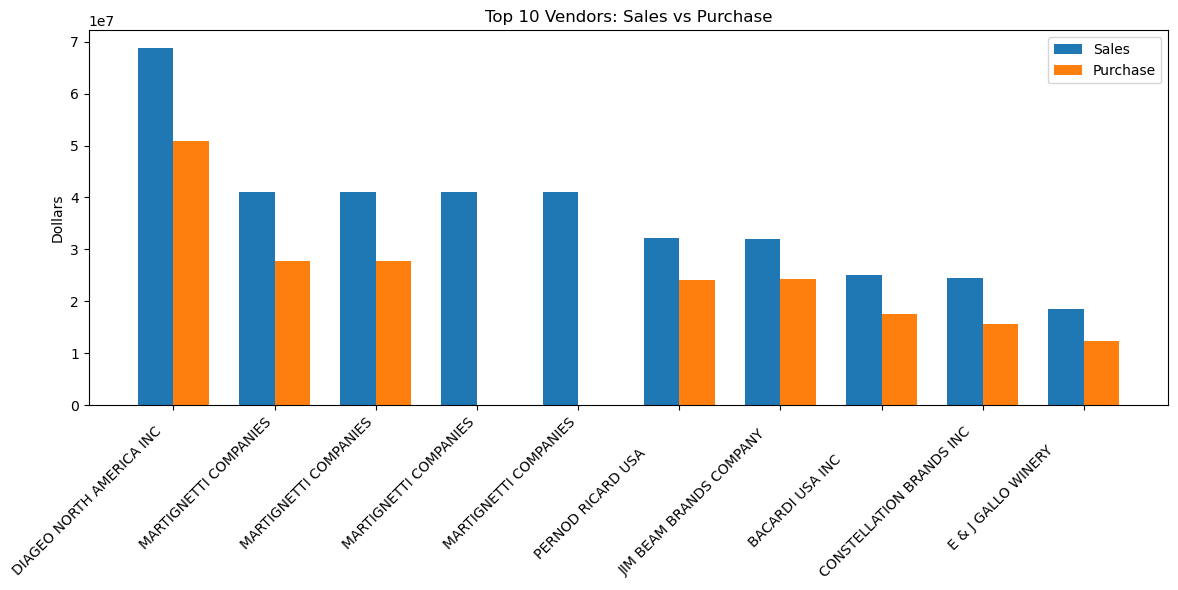

In [37]:
#sales vs purchase visualization
plt.figure(figsize=(12, 6))

top10 = (
    vendor_sales_summary
    .sort_values('TotalSalesDollars', ascending=False)
    .head(10)
)

x = np.arange(len(top10))
width = 0.35

plt.bar(
    x - width/2,
    top10['TotalSalesDollars'],
    width,
    label='Sales'
)

plt.bar(
    x + width/2,
    top10['TotalPurchaseDollars'],
    width,
    label='Purchase'
)

plt.xticks(
    x,
    top10['VendorName'],
    rotation=45,
    ha='right'
)

plt.ylabel('Dollars')
plt.title('Top 10 Vendors: Sales vs Purchase')
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# ============================================================
# VENDOR LEVEL SALES SUMMARY
# ============================================================

vendor_sales = (
    sales
    .groupby(['VendorNo', 'VendorName'], as_index=False)
    .agg(
        TotalSalesDollars=('SalesDollars', 'sum'),
        TotalSalesQuantity=('SalesQuantity', 'sum')
    )
)

print("Vendor Sales Summary Shape:", vendor_sales.shape)

display(vendor_sales.head(10))

Vendor Sales Summary Shape: (130, 4)


,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978
2,105,ALTAMAR BRANDS LLC,15748.75,325
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103
4,287,APPOLO VINEYARDS LLC,1616.92,108
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825
6,480,BACARDI USA INC,25014556.89,1457301
7,516,BANFI PRODUCTS CORP,2646325.62,221040
8,653,STATE WINE & SPIRITS,2299075.40,157700
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413


In [39]:
# ============================================================
# VENDOR LEVEL PURCHASE SUMMARY
# ============================================================

vendor_purchases = (
    purchases
    .groupby(['VendorNumber', 'VendorName'], as_index=False)
    .agg(
        TotalPurchaseDollars=('Dollars', 'sum'),
        TotalPurchaseQuantity=('Quantity', 'sum')
    )
)

print("Vendor Purchase Summary Shape:", vendor_purchases.shape)

display(vendor_purchases.head(10))

Vendor Purchase Summary Shape: (129, 4)


,VendorNumber,VendorName,TotalPurchaseDollars,TotalPurchaseQuantity
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,328
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07,1
2,60,ADAMBA IMPORTS INTL INC,76770.25,4732
3,105,ALTAMAR BRANDS LLC,11706.20,332
4,200,AMERICAN SPIRITS EXCHANGE,1205.16,132
5,287,APPOLO VINEYARDS LLC,2399.70,230
6,388,ATLANTIC IMPORTING COMPANY,41116.32,1847
7,480,BACARDI USA INC,17624378.72,1427075
8,516,BANFI PRODUCTS CORP,1628866.68,228103
9,653,STATE WINE & SPIRITS,1529682.04,154092


In [40]:
# ============================================================
# MERGE VENDOR SALES + PURCHASES
# ============================================================

vendor_sales_summary = vendor_sales.merge(
    vendor_purchases,
    left_on='VendorNo',
    right_on='VendorNumber',
    how='left'
)

# Purchase-side duplicate columns remove
vendor_sales_summary.drop(
    columns=['VendorNumber', 'VendorName_y'],
    inplace=True,
    errors='ignore'
)

vendor_sales_summary.rename(
    columns={'VendorName_x': 'VendorName'},
    inplace=True
)

display(vendor_sales_summary.head(10))

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,TotalPurchaseDollars,TotalPurchaseQuantity
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,5630.88,328.0
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,76770.25,4732.0
2,105,ALTAMAR BRANDS LLC,15748.75,325,11706.20,332.0
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,1205.16,132.0
4,287,APPOLO VINEYARDS LLC,1616.92,108,2399.70,230.0
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,41116.32,1847.0
6,480,BACARDI USA INC,25014556.89,1457301,17624378.72,1427075.0
7,516,BANFI PRODUCTS CORP,2646325.62,221040,1628866.68,228103.0
8,653,STATE WINE & SPIRITS,2299075.40,157700,1529682.04,154092.0
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,3537977.55,503931.0


In [41]:
# ============================================================
# PROFIT & MARGIN
# ============================================================

vendor_sales_summary['GrossProfit'] = (
    vendor_sales_summary['TotalSalesDollars']
    - vendor_sales_summary['TotalPurchaseDollars']
)

vendor_sales_summary['ProfitMargin'] = np.where(
    vendor_sales_summary['TotalSalesDollars'] != 0,
    (
        vendor_sales_summary['GrossProfit']
        / vendor_sales_summary['TotalSalesDollars']
    ) * 100,
    0
)

display(
    vendor_sales_summary.sort_values(
        'TotalSalesDollars',
        ascending=False
    ).head(10)
)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,TotalPurchaseDollars,TotalPurchaseQuantity,GrossProfit,ProfitMargin
46,3960,DIAGEO NORTH AMERICA INC,68742416.99,5422703,50959796.85,5459788.0,17782620.14,25.868483
49,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,40216.11,3136.0,40952179.82,99.901894
48,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,27821473.91,2637275.0,13170922.02,32.130159
108,17035,PERNOD RICARD USA,32281247.95,1613460,24124091.56,1647558.0,8157156.39,25.269024
104,12546,JIM BEAM BRANDS COMPANY,31906320.54,2630226,24203151.05,2737165.0,7703169.49,24.143083
6,480,BACARDI USA INC,25014556.89,1457301,17624378.72,1427075.0,7390178.17,29.543510
16,1392,CONSTELLATION BRANDS INC,24469172.93,2301688,15573917.90,2325892.0,8895255.03,36.352904
40,3252,E & J GALLO WINERY,18556085.61,1809023,12289608.09,1858260.0,6266477.52,33.770471
12,1128,BROWN-FORMAN CORP,18478557.47,983853,13529433.08,1006122.0,4949124.39,26.783067
88,9165,ULTRA BEVERAGE COMPANY LLP,17822938.45,1043235,13210613.93,1077527.0,4612324.52,25.878586


In [42]:
# ============================================================
# VENDOR INVOICE SUMMARY
# ============================================================

vendor_invoice_summary = (
    vendor_invoice
    .groupby(['VendorNumber', 'VendorName'], as_index=False)
    .agg(
        TotalInvoiceDollars=('Dollars', 'sum'),
        TotalFreight=('Freight', 'sum'),
        TotalInvoiceQuantity=('Quantity', 'sum'),
        TotalPurchaseOrders=('PONumber', 'nunique')
    )
)

display(vendor_invoice_summary.head(10))

,VendorNumber,VendorName,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,27.08,328,4
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07,0.48,1,1
2,60,ADAMBA IMPORTS INTL INC,76770.25,367.52,4732,35
3,105,ALTAMAR BRANDS LLC,11706.20,62.39,332,40
4,200,AMERICAN SPIRITS EXCHANGE,1205.16,6.19,132,6
5,287,APPOLO VINEYARDS LLC,2399.70,12.28,230,13
6,388,ATLANTIC IMPORTING COMPANY,41116.32,211.74,1847,53
7,480,BACARDI USA INC,17624378.72,89286.27,1427075,55
8,516,BANFI PRODUCTS CORP,1628866.68,8510.41,228103,55
9,653,STATE WINE & SPIRITS,1529682.04,8014.98,154092,55


In [43]:
# ============================================================
# FINAL VENDOR PERFORMANCE TABLE
# ============================================================

vendor_sales_summary = vendor_sales_summary.merge(
    vendor_invoice_summary,
    left_on='VendorNo',
    right_on='VendorNumber',
    how='left'
)

vendor_sales_summary.drop(
    columns=['VendorNumber', 'VendorName_y'],
    inplace=True,
    errors='ignore'
)

vendor_sales_summary.rename(
    columns={'VendorName_x': 'VendorName'},
    inplace=True
)

# Missing invoice values
numeric_cols = [
    'TotalInvoiceDollars',
    'TotalFreight',
    'TotalInvoiceQuantity',
    'TotalPurchaseOrders'
]

for col in numeric_cols:
    vendor_sales_summary[col] = (
        vendor_sales_summary[col].fillna(0)
    )

display(vendor_sales_summary.head(10))

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,TotalPurchaseDollars,TotalPurchaseQuantity,GrossProfit,ProfitMargin,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,5630.88,328.0,-4365.30,-344.924857,5630.88,27.08,328.0,4.0
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,76770.25,4732.0,-9194.03,-13.605422,76770.25,367.52,4732.0,35.0
2,105,ALTAMAR BRANDS LLC,15748.75,325,11706.20,332.0,4042.55,25.669021,11706.20,62.39,332.0,40.0
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,1205.16,132.0,514.81,29.931336,1205.16,6.19,132.0,6.0
4,287,APPOLO VINEYARDS LLC,1616.92,108,2399.70,230.0,-782.78,-48.411795,2399.70,12.28,230.0,13.0
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,41116.32,1847.0,18156.43,30.632002,41116.32,211.74,1847.0,53.0
6,480,BACARDI USA INC,25014556.89,1457301,17624378.72,1427075.0,7390178.17,29.543510,17624378.72,89286.27,1427075.0,55.0
7,516,BANFI PRODUCTS CORP,2646325.62,221040,1628866.68,228103.0,1017458.94,38.447987,1628866.68,8510.41,228103.0,55.0
8,653,STATE WINE & SPIRITS,2299075.40,157700,1529682.04,154092.0,769393.36,33.465338,1529682.04,8014.98,154092.0,55.0
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,3537977.55,503931.0,1427083.92,28.742523,3537977.55,17932.33,503931.0,55.0


In [44]:
# ============================================================
# FREIGHT ADJUSTED PROFITABILITY
# ============================================================

vendor_sales_summary['ProfitAfterFreight'] = (
    vendor_sales_summary['GrossProfit']
    - vendor_sales_summary['TotalFreight']
)

vendor_sales_summary['MarginAfterFreight'] = np.where(
    vendor_sales_summary['TotalSalesDollars'] != 0,
    (
        vendor_sales_summary['ProfitAfterFreight']
        / vendor_sales_summary['TotalSalesDollars']
    ) * 100,
    0
)

display(
    vendor_sales_summary.sort_values(
        'GrossProfit',
        ascending=False
    ).head(10)
)

,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,TotalPurchaseDollars,TotalPurchaseQuantity,GrossProfit,ProfitMargin,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,ProfitAfterFreight,MarginAfterFreight
58,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,40216.11,3136.0,40952179.82,99.901894,27821473.91,144719.92,2637275.0,55.0,40807459.90,99.548853
59,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,40216.11,3136.0,40952179.82,99.901894,40216.11,209.32,3136.0,27.0,40951970.50,99.901383
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,5422703,50959796.85,5459788.0,17782620.14,25.868483,50959796.85,257032.07,5459788.0,55.0,17525588.07,25.494576
57,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,27821473.91,2637275.0,13170922.02,32.130159,40216.11,209.32,3136.0,27.0,13170712.70,32.129648
56,4425,MARTIGNETTI COMPANIES,40992395.93,2578355,27821473.91,2637275.0,13170922.02,32.130159,27821473.91,144719.92,2637275.0,55.0,13026202.10,31.777118
16,1392,CONSTELLATION BRANDS INC,24469172.93,2301688,15573917.90,2325892.0,8895255.03,36.352904,15573917.90,79528.99,2325892.0,55.0,8815726.04,36.027887
120,17035,PERNOD RICARD USA,32281247.95,1613460,24124091.56,1647558.0,8157156.39,25.269024,24124091.56,123780.22,1647558.0,55.0,8033376.17,24.885581
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,2630226,24203151.05,2737165.0,7703169.49,24.143083,24203151.05,123880.97,2737165.0,55.0,7579288.52,23.754818
6,480,BACARDI USA INC,25014556.89,1457301,17624378.72,1427075.0,7390178.17,29.543510,17624378.72,89286.27,1427075.0,55.0,7300891.90,29.186573
48,3252,E & J GALLO WINERY,18556085.61,1809023,12289608.09,1858260.0,6266477.52,33.770471,12289608.09,61966.91,1858260.0,55.0,6204510.61,33.436527


In [45]:
# ============================================================
# OVERALL BUSINESS SUMMARY
# ============================================================

total_sales = vendor_sales_summary['TotalSalesDollars'].sum()
total_purchase = vendor_sales_summary['TotalPurchaseDollars'].sum()
total_profit = vendor_sales_summary['GrossProfit'].sum()

overall_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print("Total Vendors       :", vendor_sales_summary['VendorNo'].nunique())
print("Total Sales         :", round(total_sales, 2))
print("Total Purchase Cost :", round(total_purchase, 2))
print("Gross Profit        :", round(total_profit, 2))
print("Overall Margin %    :", round(overall_margin, 2))

Total Vendors       : 127
Total Sales         : 598063358.38
Total Purchase Cost : 420328784.68
Gross Profit        : 177734468.75
Overall Margin %    : 29.72


In [46]:
# ============================================================
# TOP 10 VENDORS
# ============================================================

print("TOP 10 VENDORS BY SALES")
display(
    vendor_sales_summary
    .sort_values('TotalSalesDollars', ascending=False)
    [['VendorNo', 'VendorName',
      'TotalSalesDollars',
      'TotalPurchaseDollars',
      'GrossProfit',
      'ProfitMargin']]
    .head(10)
)

TOP 10 VENDORS BY SALES


,VendorNo,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,50959796.85,17782620.14,25.868483
56,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,13170922.02,32.130159
57,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,13170922.02,32.130159
59,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,40952179.82,99.901894
58,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,40952179.82,99.901894
120,17035,PERNOD RICARD USA,32281247.95,24124091.56,8157156.39,25.269024
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,24203151.05,7703169.49,24.143083
6,480,BACARDI USA INC,25014556.89,17624378.72,7390178.17,29.543510
16,1392,CONSTELLATION BRANDS INC,24469172.93,15573917.90,8895255.03,36.352904
48,3252,E & J GALLO WINERY,18556085.61,12289608.09,6266477.52,33.770471


In [47]:
print("TOP 10 VENDORS BY GROSS PROFIT")
display(
    vendor_sales_summary
    .sort_values('GrossProfit', ascending=False)
    [['VendorNo', 'VendorName',
      'TotalSalesDollars',
      'TotalPurchaseDollars',
      'GrossProfit',
      'ProfitMargin']]
    .head(10)
)

TOP 10 VENDORS BY GROSS PROFIT


,VendorNo,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
58,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,40952179.82,99.901894
59,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,40952179.82,99.901894
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,50959796.85,17782620.14,25.868483
57,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,13170922.02,32.130159
56,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,13170922.02,32.130159
16,1392,CONSTELLATION BRANDS INC,24469172.93,15573917.90,8895255.03,36.352904
120,17035,PERNOD RICARD USA,32281247.95,24124091.56,8157156.39,25.269024
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,24203151.05,7703169.49,24.143083
6,480,BACARDI USA INC,25014556.89,17624378.72,7390178.17,29.543510
48,3252,E & J GALLO WINERY,18556085.61,12289608.09,6266477.52,33.770471


In [48]:
# ============================================================
# INVENTORY ANALYSIS
# ============================================================

print("BEGIN INVENTORY")
print("Rows:", len(begin_inventory))
print("Unique Stores:", begin_inventory['Store'].nunique())
print("Unique Products:", begin_inventory['Brand'].nunique())

print("\nEND INVENTORY")
print("Rows:", len(end_inventory))
print("Unique Stores:", end_inventory['Store'].nunique())
print("Unique Products:", end_inventory['Brand'].nunique())

BEGIN INVENTORY
Rows: 206529
Unique Stores: 79
Unique Products: 8094

END INVENTORY
Rows: 224489
Unique Stores: 80
Unique Products: 9653


In [49]:
# ============================================================
# INVENTORY CHANGE
# ============================================================

begin_stock = (
    begin_inventory
    .groupby('InventoryId', as_index=False)
    .agg(BeginStock=('onHand', 'sum'))
)

end_stock = (
    end_inventory
    .groupby('InventoryId', as_index=False)
    .agg(EndStock=('onHand', 'sum'))
)

inventory_change = begin_stock.merge(
    end_stock,
    on='InventoryId',
    how='outer'
)

inventory_change[['BeginStock', 'EndStock']] = (
    inventory_change[['BeginStock', 'EndStock']]
    .fillna(0)
)

inventory_change['StockChange'] = (
    inventory_change['EndStock']
    - inventory_change['BeginStock']
)

display(inventory_change.head(10))

,InventoryId,BeginStock,EndStock,StockChange
0,10_HORNSEY_1000,1.0,0.0,-1.0
1,10_HORNSEY_1001,11.0,0.0,-11.0
2,10_HORNSEY_1003,0.0,73.0,73.0
3,10_HORNSEY_1005,18.0,0.0,-18.0
4,10_HORNSEY_10058,52.0,24.0,-28.0
5,10_HORNSEY_1006,1.0,0.0,-1.0
6,10_HORNSEY_10062,11.0,15.0,4.0
7,10_HORNSEY_1009,3.0,0.0,-3.0
8,10_HORNSEY_1012,2.0,0.0,-2.0
9,10_HORNSEY_1013,5.0,0.0,-5.0


In [50]:
# ============================================================
# STOCK DECREASE
# ============================================================

stock_decreased = (
    inventory_change[
        inventory_change['StockChange'] < 0
    ]
    .sort_values('StockChange')
)

print("Products with decreased stock:",
      len(stock_decreased))

display(stock_decreased.head(20))

Products with decreased stock: 110157


,InventoryId,BeginStock,EndStock,StockChange
77809,34_PITMERDEN_3876,930.0,107.0,-823.0
241654,79_BALLYMENA_3859,1163.0,351.0,-812.0
178667,65_LUTON_7341,921.0,144.0,-777.0
77792,34_PITMERDEN_3858,818.0,88.0,-730.0
200323,69_MOUNTMEND_3858,1251.0,527.0,-724.0
183131,66_EANVERNESS_3876,597.0,25.0,-572.0
90685,38_GOULCREST_6570,706.0,184.0,-522.0
232563,76_DONCASTER_3876,541.0,19.0,-522.0
76261,34_PITMERDEN_2663,576.0,93.0,-483.0
79508,34_PITMERDEN_8082,503.0,35.0,-468.0


In [51]:
# ============================================================
# STOCK INCREASE
# ============================================================

stock_increased = (
    inventory_change[
        inventory_change['StockChange'] > 0
    ]
    .sort_values('StockChange', ascending=False)
)

print("Products with increased stock:",
      len(stock_increased))

display(stock_increased.head(20))

Products with increased stock: 128639


,InventoryId,BeginStock,EndStock,StockChange
133804,50_MOUNTMEND_5609,0.0,3676.0,3676.0
190329,67_EANVERNESS_5111,164.0,3005.0,2841.0
133806,50_MOUNTMEND_5614,0.0,1778.0,1778.0
133802,50_MOUNTMEND_5598,0.0,1689.0,1689.0
134243,50_MOUNTMEND_754,0.0,1591.0,1591.0
134492,50_MOUNTMEND_8500,0.0,1222.0,1222.0
129764,50_MOUNTMEND_2277,0.0,1220.0,1220.0
167648,61_AETHELNEY_3224,0.0,1002.0,1002.0
190487,67_EANVERNESS_5609,0.0,932.0,932.0
131727,50_MOUNTMEND_3102,300.0,1227.0,927.0


In [52]:
# ============================================================
# ADD PRODUCT DETAILS
# ============================================================

product_details = (
    begin_inventory[
        ['InventoryId', 'Store', 'City', 'Brand', 'Description', 'Size', 'Price']
    ]
    .drop_duplicates('InventoryId')
)

inventory_change = inventory_change.merge(
    product_details,
    on='InventoryId',
    how='left'
)

display(inventory_change.head(10))

,InventoryId,BeginStock,EndStock,StockChange,Store,City,Brand,Description,Size,Price
0,10_HORNSEY_1000,1.0,0.0,-1.0,10.0,HORNSEY,1000.0,Goslings Dark'n Stormy VAP,750mL,14.99
1,10_HORNSEY_1001,11.0,0.0,-11.0,10.0,HORNSEY,1001.0,Baileys 50mL 4 Pack,50mL 4 Pk,5.99
2,10_HORNSEY_1003,0.0,73.0,73.0,NaN,NaN,NaN,NaN,NaN,NaN
3,10_HORNSEY_1005,18.0,0.0,-18.0,10.0,HORNSEY,1005.0,Maker's Mark Combo Pack,375mL 2 Pk,34.99
4,10_HORNSEY_10058,52.0,24.0,-28.0,10.0,HORNSEY,10058.0,F Coppola Dmd Ivry Cab Svgn,750mL,14.99
5,10_HORNSEY_1006,1.0,0.0,-1.0,10.0,HORNSEY,1006.0,Jim Beam Candy Cane 4/50mLs,50mL 4 Pk,3.99
6,10_HORNSEY_10062,11.0,15.0,4.0,10.0,HORNSEY,10062.0,Terroirs du Rhone,750mL,8.99
7,10_HORNSEY_1009,3.0,0.0,-3.0,10.0,HORNSEY,1009.0,Rebel Yell Variety Pack,750mL 3 Pk,49.99
8,10_HORNSEY_1012,2.0,0.0,-2.0,10.0,HORNSEY,1012.0,Courvoisier VSOP VAP,750mL,34.99
9,10_HORNSEY_1013,5.0,0.0,-5.0,10.0,HORNSEY,1013.0,Kahlua Pumpkin Spice Liqueur,750mL,18.99


In [53]:
# ============================================================
# INVENTORY VALUE
# ============================================================

inventory_change['BeginInventoryValue'] = (
    inventory_change['BeginStock']
    * inventory_change['Price']
)

inventory_change['EndInventoryValue'] = (
    inventory_change['EndStock']
    * inventory_change['Price']
)

inventory_change['InventoryValueChange'] = (
    inventory_change['EndInventoryValue']
    - inventory_change['BeginInventoryValue']
)

display(
    inventory_change[
        [
            'InventoryId',
            'Description',
            'BeginStock',
            'EndStock',
            'StockChange',
            'BeginInventoryValue',
            'EndInventoryValue',
            'InventoryValueChange'
        ]
    ].head(20)
)

,InventoryId,Description,BeginStock,EndStock,StockChange,BeginInventoryValue,EndInventoryValue,InventoryValueChange
0,10_HORNSEY_1000,Goslings Dark'n Stormy VAP,1.0,0.0,-1.0,14.99,0.00,-14.99
1,10_HORNSEY_1001,Baileys 50mL 4 Pack,11.0,0.0,-11.0,65.89,0.00,-65.89
2,10_HORNSEY_1003,NaN,0.0,73.0,73.0,NaN,NaN,NaN
3,10_HORNSEY_1005,Maker's Mark Combo Pack,18.0,0.0,-18.0,629.82,0.00,-629.82
4,10_HORNSEY_10058,F Coppola Dmd Ivry Cab Svgn,52.0,24.0,-28.0,779.48,359.76,-419.72
5,10_HORNSEY_1006,Jim Beam Candy Cane 4/50mLs,1.0,0.0,-1.0,3.99,0.00,-3.99
6,10_HORNSEY_10062,Terroirs du Rhone,11.0,15.0,4.0,98.89,134.85,35.96
7,10_HORNSEY_1009,Rebel Yell Variety Pack,3.0,0.0,-3.0,149.97,0.00,-149.97
8,10_HORNSEY_1012,Courvoisier VSOP VAP,2.0,0.0,-2.0,69.98,0.00,-69.98
9,10_HORNSEY_1013,Kahlua Pumpkin Spice Liqueur,5.0,0.0,-5.0,94.95,0.00,-94.95


In [54]:
# ============================================================
# PRODUCT LEVEL SALES ANALYSIS
# ============================================================

product_sales = (
    sales
    .groupby(
        ['Brand', 'Description', 'Size', 'VendorNo', 'VendorName'],
        as_index=False
    )
    .agg(
        TotalSalesQuantity=('SalesQuantity', 'sum'),
        TotalSalesDollars=('SalesDollars', 'sum'),
        AverageSalesPrice=('SalesPrice', 'mean')
    )
)

print("Product Sales Shape:", product_sales.shape)

display(
    product_sales
    .sort_values('TotalSalesDollars', ascending=False)
    .head(20)
)

Product Sales Shape: (11277, 8)


,Brand,Description,Size,VendorNo,VendorName,TotalSalesQuantity,TotalSalesDollars,AverageSalesPrice
612,1233,Jack Daniels No 7 Black,1.75L,1128,BROWN-FORMAN CORP,142049,5101919.51,36.233470
1725,3405,Tito's Handmade Vodka,1.75L,4425,MARTIGNETTI COMPANIES,160247,4819073.49,30.314332
3324,8068,Absolut 80 Proof,1.75L,17035,PERNOD RICARD USA,187140,4538120.60,24.483151
2242,4261,Capt Morgan Spiced Rum,1.75L,3960,DIAGEO NORTH AMERICA INC,200412,4475972.88,22.830046
1812,3545,Ketel One Vodka,1.75L,3960,DIAGEO NORTH AMERICA INC,135838,4223107.62,31.417124
2024,3858,Grey Goose Vodka,750mL,480,BACARDI USA INC,141860,3383912.40,24.568858
1201,2589,Jameson Irish Whiskey,1.75L,17035,PERNOD RICARD USA,69627,2773367.73,40.520199
1779,3489,Tanqueray,1.75L,3960,DIAGEO NORTH AMERICA INC,90481,2640491.19,29.457306
1549,3102,Smirnoff Traveler,1.75L,3960,DIAGEO NORTH AMERICA INC,148265,2592041.35,17.656526
676,1376,Jim Beam,1.75L,12546,JIM BEAM BRANDS COMPANY,107061,2435393.39,23.048417


In [55]:
# ============================================================
# PRODUCT LEVEL PURCHASE ANALYSIS
# ============================================================

product_purchase = (
    purchases
    .groupby(
        ['Brand', 'Description', 'Size', 'VendorNumber', 'VendorName'],
        as_index=False
    )
    .agg(
        TotalPurchaseQuantity=('Quantity', 'sum'),
        TotalPurchaseDollars=('Dollars', 'sum'),
        AveragePurchasePrice=('PurchasePrice', 'mean')
    )
)

print("Product Purchase Shape:", product_purchase.shape)

display(
    product_purchase
    .sort_values('TotalPurchaseDollars', ascending=False)
    .head(20)
)

Product Purchase Shape: (10696, 8)


,Brand,Description,Size,VendorNumber,VendorName,TotalPurchaseQuantity,TotalPurchaseDollars,AveragePurchasePrice
573,1233,Jack Daniels No 7 Black,1.75L,1128,BROWN-FORMAN CORP,145080,3811251.60,26.27
1636,3405,Tito's Handmade Vodka,1.75L,4425,MARTIGNETTI COMPANIES,164038,3804041.22,23.19
3178,8068,Absolut 80 Proof,1.75L,17035,PERNOD RICARD USA,187407,3418303.68,18.24
2129,4261,Capt Morgan Spiced Rum,1.75L,3960,DIAGEO NORTH AMERICA INC,201682,3261197.94,16.17
1717,3545,Ketel One Vodka,1.75L,3960,DIAGEO NORTH AMERICA INC,138109,3023206.01,21.89
1918,3858,Grey Goose Vodka,750mL,480,BACARDI USA INC,138809,2466635.93,17.77
1143,2589,Jameson Irish Whiskey,1.75L,17035,PERNOD RICARD USA,70783,2177285.08,30.76
1471,3102,Smirnoff Traveler,1.75L,3960,DIAGEO NORTH AMERICA INC,161386,2088334.84,12.94
1685,3489,Tanqueray,1.75L,3960,DIAGEO NORTH AMERICA INC,91835,1903739.55,20.73
633,1376,Jim Beam,1.75L,12546,JIM BEAM BRANDS COMPANY,108866,1773427.14,16.29


In [56]:
# ============================================================
# MERGE PRODUCT SALES + PURCHASES
# ============================================================

product_analysis = product_sales.merge(
    product_purchase,
    left_on=[
        'Brand',
        'Description',
        'Size',
        'VendorNo',
        'VendorName'
    ],
    right_on=[
        'Brand',
        'Description',
        'Size',
        'VendorNumber',
        'VendorName'
    ],
    how='left'
)

product_analysis.drop(
    columns=['VendorNumber'],
    inplace=True,
    errors='ignore'
)

# Missing purchase values = 0
numeric_cols = [
    'TotalPurchaseQuantity',
    'TotalPurchaseDollars',
    'AveragePurchasePrice'
]

for col in numeric_cols:
    product_analysis[col] = product_analysis[col].fillna(0)

display(product_analysis.head(20))

,Brand,Description,Size,VendorNo,VendorName,TotalSalesQuantity,TotalSalesDollars,AverageSalesPrice,TotalPurchaseQuantity,TotalPurchaseDollars,AveragePurchasePrice
0,58,Gekkeikan Black & Gold Sake,750mL,8320,SHAW ROSS INT L IMP LTD,3446,43341.54,12.587496,3550.0,32944.00,9.28
1,60,Canadian Club 1858 VAP,750mL,12546,JIM BEAM BRANDS COMPANY,1775,18716.25,10.500284,1633.0,12084.20,7.40
2,61,Margaritaville Silver,750mL,8004,SAZERAC CO INC,312,4364.88,13.990000,312.0,3307.20,10.60
3,62,Herradura Silver Tequila,750mL,1128,BROWN-FORMAN CORP,3125,119863.75,38.379953,3200.0,91744.00,28.67
4,63,Herradura Reposado Tequila,750mL,1128,BROWN-FORMAN CORP,2778,112249.22,40.435205,2855.0,86963.30,30.46
5,70,Luxardo Amaretto di Saschira,750mL,9165,ULTRA BEVERAGE COMPANY LLP,14,349.86,24.990000,14.0,195.44,13.96
6,72,No. 3 London Dry Gin,750mL,9165,ULTRA BEVERAGE COMPANY LLP,469,17325.31,36.812157,457.0,11932.27,26.11
7,75,Three Olives Tomato Vodka,750mL,7245,PROXIMO SPIRITS INC.,21,314.79,14.990000,10.0,109.40,10.94
8,77,Three Olives Espresso Vodka,750mL,7245,PROXIMO SPIRITS INC.,10429,143416.71,13.771029,10932.0,113583.48,10.39
9,79,Three Olives Loopy Vodka,750mL,7245,PROXIMO SPIRITS INC.,5686,78923.14,13.933842,5779.0,55593.98,9.62


In [57]:
# ============================================================
# PRODUCT PROFITABILITY
# ============================================================

product_analysis['GrossProfit'] = (
    product_analysis['TotalSalesDollars']
    - product_analysis['TotalPurchaseDollars']
)

product_analysis['ProfitMargin'] = np.where(
    product_analysis['TotalSalesDollars'] != 0,
    (
        product_analysis['GrossProfit']
        / product_analysis['TotalSalesDollars']
    ) * 100,
    0
)

display(
    product_analysis[
        [
            'Brand',
            'Description',
            'VendorNo',
            'VendorName',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'GrossProfit',
            'ProfitMargin'
        ]
    ]
    .sort_values('GrossProfit', ascending=False)
    .head(20)
)

,Brand,Description,VendorNo,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
612,1233,Jack Daniels No 7 Black,1128,BROWN-FORMAN CORP,5101919.51,3811251.60,1290667.91,25.297693
2242,4261,Capt Morgan Spiced Rum,3960,DIAGEO NORTH AMERICA INC,4475972.88,3261197.94,1214774.94,27.139908
1812,3545,Ketel One Vodka,3960,DIAGEO NORTH AMERICA INC,4223107.62,3023206.01,1199901.61,28.412764
3324,8068,Absolut 80 Proof,17035,PERNOD RICARD USA,4538120.60,3418303.68,1119816.92,24.675786
1725,3405,Tito's Handmade Vodka,4425,MARTIGNETTI COMPANIES,4819073.49,3804041.22,1015032.27,21.062810
2024,3858,Grey Goose Vodka,480,BACARDI USA INC,3383912.40,2466635.93,917276.47,27.106980
3037,6570,Kendall Jackson Chard Vt RSV,10000,MAJESTIC FINE WINES,2326007.78,1460072.36,865935.42,37.228397
1779,3489,Tanqueray,3960,DIAGEO NORTH AMERICA INC,2640491.19,1903739.55,736751.64,27.902068
1254,2663,Dewars White Label,480,BACARDI USA INC,2189368.78,1478001.42,711367.36,32.491893
3333,8082,Baileys Irish Cream,3960,DIAGEO NORTH AMERICA INC,2068091.16,1396130.77,671960.39,32.491817


In [58]:
# ============================================================
# SALES PRICE VS PURCHASE PRICE
# ============================================================

product_analysis['PriceDifference'] = (
    product_analysis['AverageSalesPrice']
    - product_analysis['AveragePurchasePrice']
)

product_analysis['ProductMarginPercent'] = np.where(
    product_analysis['AverageSalesPrice'] != 0,
    (
        product_analysis['PriceDifference']
        / product_analysis['AverageSalesPrice']
    ) * 100,
    0
)

display(
    product_analysis[
        [
            'Brand',
            'Description',
            'VendorName',
            'AveragePurchasePrice',
            'AverageSalesPrice',
            'PriceDifference',
            'ProductMarginPercent'
        ]
    ]
    .sort_values('ProductMarginPercent', ascending=False)
    .head(20)
)

,Brand,Description,VendorName,AveragePurchasePrice,AverageSalesPrice,PriceDifference,ProductMarginPercent
1820,3563,Smirnoff Sours Fruit Punch,DIAGEO NORTH AMERICA INC,0.0,9.49,9.49,100.0
7148,22634,Buil & Gine Priorat Red,VINEXTRA INC,0.0,20.99,20.99,100.0
10659,41780,Stoneleigh Svgn Bl Marlboro,PERNOD RICARD USA,0.0,9.99,9.99,100.0
7147,22633,Buil & Gine Priorat White,VINEXTRA INC,0.0,23.99,23.99,100.0
6434,20842,Papi Merlot,PINE STATE TRADING CO,0.0,8.49,8.49,100.0
4869,16169,Vina Cobos Bramare Malbec,MARTIGNETTI COMPANIES,0.0,39.99,39.99,100.0
6435,20853,The Beautiful Syrah Walla,PERFECTA WINES,0.0,59.99,59.99,100.0
3438,8348,Cabrito Reposado,PHILLIPS PRODUCTS CO.,0.0,17.99,17.99,100.0
7141,22622,A Bichot Savigny Beaune,ULTRA BEVERAGE COMPANY LLP,0.0,48.99,48.99,100.0
7139,22620,Victor Vyds Old Vine Znfdl,ULTRA BEVERAGE COMPANY LLP,0.0,8.99,8.99,100.0


In [59]:
# ============================================================
# TOP SELLING PRODUCTS
# ============================================================

top_products = (
    product_analysis
    .sort_values(
        'TotalSalesDollars',
        ascending=False
    )
    .head(20)
)

display(
    top_products[
        [
            'Brand',
            'Description',
            'Size',
            'VendorName',
            'TotalSalesQuantity',
            'TotalSalesDollars',
            'AverageSalesPrice',
            'GrossProfit',
            'ProfitMargin'
        ]
    ]
)

,Brand,Description,Size,VendorName,TotalSalesQuantity,TotalSalesDollars,AverageSalesPrice,GrossProfit,ProfitMargin
612,1233,Jack Daniels No 7 Black,1.75L,BROWN-FORMAN CORP,142049,5101919.51,36.233470,1290667.91,25.297693
1725,3405,Tito's Handmade Vodka,1.75L,MARTIGNETTI COMPANIES,160247,4819073.49,30.314332,1015032.27,21.062810
3324,8068,Absolut 80 Proof,1.75L,PERNOD RICARD USA,187140,4538120.60,24.483151,1119816.92,24.675786
2242,4261,Capt Morgan Spiced Rum,1.75L,DIAGEO NORTH AMERICA INC,200412,4475972.88,22.830046,1214774.94,27.139908
1812,3545,Ketel One Vodka,1.75L,DIAGEO NORTH AMERICA INC,135838,4223107.62,31.417124,1199901.61,28.412764
2024,3858,Grey Goose Vodka,750mL,BACARDI USA INC,141860,3383912.40,24.568858,917276.47,27.106980
1201,2589,Jameson Irish Whiskey,1.75L,PERNOD RICARD USA,69627,2773367.73,40.520199,596082.65,21.493098
1779,3489,Tanqueray,1.75L,DIAGEO NORTH AMERICA INC,90481,2640491.19,29.457306,736751.64,27.902068
1549,3102,Smirnoff Traveler,1.75L,DIAGEO NORTH AMERICA INC,148265,2592041.35,17.656526,503706.51,19.432812
676,1376,Jim Beam,1.75L,JIM BEAM BRANDS COMPANY,107061,2435393.39,23.048417,661966.25,27.181081


In [60]:
# ============================================================
# LOW MARGIN PRODUCTS
# ============================================================

low_margin_products = (
    product_analysis[
        product_analysis['TotalSalesDollars'] > 0
    ]
    .sort_values('ProfitMargin')
    .head(20)
)

display(
    low_margin_products[
        [
            'Brand',
            'Description',
            'VendorName',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'GrossProfit',
            'ProfitMargin'
        ]
    ]
)

,Brand,Description,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
9402,27342,19 Crimes The Banished Red,TREASURY WINE ESTATES,38.97,9286.80,-9247.83,-23730.638953
4812,15880,San Polo Brun di Montlcno 11,SOUTHERN WINE & SPIRITS NE,149.98,29214.00,-29064.02,-19378.597146
9473,27553,Hedges Family Estate Red Mtn,MARTIGNETTI COMPANIES,26.99,4049.28,-4022.29,-14902.889959
9378,27274,Jos Phelps Insignia 13,ULTRA BEVERAGE COMPANY LLP,209.99,23881.50,-23671.51,-11272.684414
9571,27969,Fattoria le Pupille Poggio,SOUTHERN GLAZERS W&S OF NE,36.99,4089.12,-4052.13,-10954.663423
7125,22591,Ch Manos Cadillac,VINILANDIA USA,15.99,1535.92,-1519.93,-9505.503440
925,2094,Kilchoman Machir Bay Whiskey,M S WALKER INC,133.98,11149.20,-11015.22,-8221.540528
4271,13557,Merry Edwards Flax Vyd Pnt N,MARTIGNETTI COMPANIES,69.99,5526.00,-5456.01,-7795.413631
4819,15901,Merry Edwards Georg Pnt Nr,MARTIGNETTI COMPANIES,79.99,5960.40,-5880.41,-7351.431429
8956,26266,The Divining Rod Pinot Noir,SOUTHERN WINE & SPIRITS NE,33.98,1525.92,-1491.94,-4390.641554


In [61]:
# ============================================================
# FINAL PRODUCT ANALYSIS TABLE
# ============================================================

product_analysis = product_analysis.sort_values(
    'TotalSalesDollars',
    ascending=False
).reset_index(drop=True)

print("Final Product Analysis Shape:", product_analysis.shape)

display(product_analysis.head(20))

Final Product Analysis Shape: (11277, 15)


,Brand,Description,Size,VendorNo,VendorName,TotalSalesQuantity,TotalSalesDollars,AverageSalesPrice,TotalPurchaseQuantity,TotalPurchaseDollars,AveragePurchasePrice,GrossProfit,ProfitMargin,PriceDifference,ProductMarginPercent
0,1233,Jack Daniels No 7 Black,1.75L,1128,BROWN-FORMAN CORP,142049,5101919.51,36.233470,145080.0,3811251.60,26.27,1290667.91,25.297693,9.963470,27.497974
1,3405,Tito's Handmade Vodka,1.75L,4425,MARTIGNETTI COMPANIES,160247,4819073.49,30.314332,164038.0,3804041.22,23.19,1015032.27,21.062810,7.124332,23.501530
2,8068,Absolut 80 Proof,1.75L,17035,PERNOD RICARD USA,187140,4538120.60,24.483151,187407.0,3418303.68,18.24,1119816.92,24.675786,6.243151,25.499786
3,4261,Capt Morgan Spiced Rum,1.75L,3960,DIAGEO NORTH AMERICA INC,200412,4475972.88,22.830046,201682.0,3261197.94,16.17,1214774.94,27.139908,6.660046,29.172284
4,3545,Ketel One Vodka,1.75L,3960,DIAGEO NORTH AMERICA INC,135838,4223107.62,31.417124,138109.0,3023206.01,21.89,1199901.61,28.412764,9.527124,30.324622
5,3858,Grey Goose Vodka,750mL,480,BACARDI USA INC,141860,3383912.40,24.568858,138809.0,2466635.93,17.77,917276.47,27.106980,6.798858,27.672665
6,2589,Jameson Irish Whiskey,1.75L,17035,PERNOD RICARD USA,69627,2773367.73,40.520199,70783.0,2177285.08,30.76,596082.65,21.493098,9.760199,24.087244
7,3489,Tanqueray,1.75L,3960,DIAGEO NORTH AMERICA INC,90481,2640491.19,29.457306,91835.0,1903739.55,20.73,736751.64,27.902068,8.727306,29.626966
8,3102,Smirnoff Traveler,1.75L,3960,DIAGEO NORTH AMERICA INC,148265,2592041.35,17.656526,161386.0,2088334.84,12.94,503706.51,19.432812,4.716526,26.712649
9,1376,Jim Beam,1.75L,12546,JIM BEAM BRANDS COMPANY,107061,2435393.39,23.048417,108866.0,1773427.14,16.29,661966.25,27.181081,6.758417,29.322695


In [62]:
# ============================================================
# VENDOR PERFORMANCE SEGMENTATION
# ============================================================

vendor_final = vendor_sales_summary.copy()

vendor_final['SalesSharePercent'] = np.where(
    vendor_final['TotalSalesDollars'].sum() != 0,
    (vendor_final['TotalSalesDollars']
     / vendor_final['TotalSalesDollars'].sum()) * 100,
    0
)

vendor_final['PurchaseSharePercent'] = np.where(
    vendor_final['TotalPurchaseDollars'].sum() != 0,
    (vendor_final['TotalPurchaseDollars']
     / vendor_final['TotalPurchaseDollars'].sum()) * 100,
    0
)

vendor_final['FreightPercentOfSales'] = np.where(
    vendor_final['TotalSalesDollars'] != 0,
    (vendor_final['TotalFreight']
     / vendor_final['TotalSalesDollars']) * 100,
    0
)

display(
    vendor_final[
        [
            'VendorNo',
            'VendorName',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'GrossProfit',
            'ProfitMargin',
            'ProfitAfterFreight',
            'MarginAfterFreight',
            'SalesSharePercent',
            'FreightPercentOfSales'
        ]
    ].head(20)
)

,VendorNo,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin,ProfitAfterFreight,MarginAfterFreight,SalesSharePercent,FreightPercentOfSales
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,5630.88,-4365.30,-344.924857,-4392.38,-347.064587,0.000212,2.139730
1,60,ADAMBA IMPORTS INTL INC,67576.22,76770.25,-9194.03,-13.605422,-9561.55,-14.149282,0.011299,0.543860
2,105,ALTAMAR BRANDS LLC,15748.75,11706.20,4042.55,25.669021,3980.16,25.272863,0.002633,0.396158
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,1205.16,514.81,29.931336,508.62,29.571446,0.000288,0.359890
4,287,APPOLO VINEYARDS LLC,1616.92,2399.70,-782.78,-48.411795,-795.06,-49.171264,0.000270,0.759469
5,388,ATLANTIC IMPORTING COMPANY,59272.75,41116.32,18156.43,30.632002,17944.69,30.274772,0.009911,0.357230
6,480,BACARDI USA INC,25014556.89,17624378.72,7390178.17,29.543510,7300891.90,29.186573,4.182593,0.356937
7,516,BANFI PRODUCTS CORP,2646325.62,1628866.68,1017458.94,38.447987,1008948.53,38.126394,0.442482,0.321593
8,653,STATE WINE & SPIRITS,2299075.40,1529682.04,769393.36,33.465338,761378.38,33.116721,0.384420,0.348618
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,3537977.55,1427083.92,28.742523,1409151.59,28.381352,0.830190,0.361170


In [63]:
# ============================================================
# TOP VENDORS AFTER FREIGHT
# ============================================================

top_profitable_vendors = (
    vendor_final
    .sort_values(
        'ProfitAfterFreight',
        ascending=False
    )
    .head(20)
)

display(
    top_profitable_vendors[
        [
            'VendorNo',
            'VendorName',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'TotalFreight',
            'ProfitAfterFreight',
            'MarginAfterFreight'
        ]
    ]
)

,VendorNo,VendorName,TotalSalesDollars,TotalPurchaseDollars,TotalFreight,ProfitAfterFreight,MarginAfterFreight
59,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,209.32,40951970.50,99.901383
58,4425,MARTIGNETTI COMPANIES,40992395.93,40216.11,144719.92,40807459.90,99.548853
54,3960,DIAGEO NORTH AMERICA INC,68742416.99,50959796.85,257032.07,17525588.07,25.494576
57,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,209.32,13170712.70,32.129648
56,4425,MARTIGNETTI COMPANIES,40992395.93,27821473.91,144719.92,13026202.10,31.777118
16,1392,CONSTELLATION BRANDS INC,24469172.93,15573917.90,79528.99,8815726.04,36.027887
120,17035,PERNOD RICARD USA,32281247.95,24124091.56,123780.22,8033376.17,24.885581
116,12546,JIM BEAM BRANDS COMPANY,31906320.54,24203151.05,123880.97,7579288.52,23.754818
6,480,BACARDI USA INC,25014556.89,17624378.72,89286.27,7300891.90,29.186573
48,3252,E & J GALLO WINERY,18556085.61,12289608.09,61966.91,6204510.61,33.436527


In [64]:
# ============================================================
# HIGH FREIGHT COST VENDORS
# ============================================================

high_freight_vendors = (
    vendor_final
    .sort_values(
        'FreightPercentOfSales',
        ascending=False
    )
    .head(20)
)

display(
    high_freight_vendors[
        [
            'VendorNo',
            'VendorName',
            'TotalSalesDollars',
            'TotalFreight',
            'FreightPercentOfSales',
            'ProfitAfterFreight'
        ]
    ]
)

,VendorNo,VendorName,TotalSalesDollars,TotalFreight,FreightPercentOfSales,ProfitAfterFreight
62,4425,MARTIGNETTI COMPANIES,54910.37,144719.92,263.556629,-130025.66
60,4425,MARTIGNETTI COMPANIES,54910.37,144719.92,263.556629,-27911283.46
23,1587,VINEYARD BRANDS LLC,4323.96,6015.86,139.128484,-1197854.71
25,1587,VINEYARD BRANDS LLC,4323.96,6015.86,139.128484,-12643.41
35,2000,SOUTHERN GLAZERS W&S OF NE,40440.12,18808.83,46.510322,-3678182.17
33,2000,SOUTHERN GLAZERS W&S OF NE,40440.12,18808.83,46.510322,-19172.63
99,9099,TRUETT HURST,14.99,1.25,8.338893,-222.90
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,27.08,2.139730,-4392.38
53,3951,HIGHLAND WINE MERCHANTS LLC,1533.68,29.43,1.918914,-3996.07
76,6280,UNCORKED,1124.38,15.26,1.357192,-1857.19


In [65]:
# ============================================================
# VENDOR PERFORMANCE CATEGORY
# ============================================================

vendor_final['PerformanceCategory'] = np.select(
    [
        (vendor_final['ProfitAfterFreight'] > 0) &
        (vendor_final['MarginAfterFreight'] >= 20),

        (vendor_final['ProfitAfterFreight'] > 0) &
        (vendor_final['MarginAfterFreight'] < 20),

        (vendor_final['ProfitAfterFreight'] <= 0)
    ],
    [
        'High Margin',
        'Low Margin',
        'Loss / Negative Profit'
    ],
    default='Unknown'
)

display(
    vendor_final[
        [
            'VendorNo',
            'VendorName',
            'ProfitAfterFreight',
            'MarginAfterFreight',
            'PerformanceCategory'
        ]
    ].head(20)
)

,VendorNo,VendorName,ProfitAfterFreight,MarginAfterFreight,PerformanceCategory
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",-4392.38,-347.064587,Loss / Negative Profit
1,60,ADAMBA IMPORTS INTL INC,-9561.55,-14.149282,Loss / Negative Profit
2,105,ALTAMAR BRANDS LLC,3980.16,25.272863,High Margin
3,200,AMERICAN SPIRITS EXCHANGE,508.62,29.571446,High Margin
4,287,APPOLO VINEYARDS LLC,-795.06,-49.171264,Loss / Negative Profit
5,388,ATLANTIC IMPORTING COMPANY,17944.69,30.274772,High Margin
6,480,BACARDI USA INC,7300891.90,29.186573,High Margin
7,516,BANFI PRODUCTS CORP,1008948.53,38.126394,High Margin
8,653,STATE WINE & SPIRITS,761378.38,33.116721,High Margin
9,660,SAZERAC NORTH AMERICA INC.,1409151.59,28.381352,High Margin


In [66]:
# ============================================================
# PERFORMANCE CATEGORY SUMMARY
# ============================================================

category_summary = (
    vendor_final
    .groupby('PerformanceCategory', as_index=False)
    .agg(
        VendorCount=('VendorNo', 'nunique'),
        TotalSales=('TotalSalesDollars', 'sum'),
        TotalProfit=('ProfitAfterFreight', 'sum')
    )
)

display(category_summary)

,PerformanceCategory,VendorCount,TotalSales,TotalProfit
0,High Margin,87,5.936910e+08,2.407457e+08
1,Loss / Negative Profit,15,6.328450e+05,-6.560882e+07
2,Low Margin,25,3.739453e+06,4.470403e+05
3,Unknown,3,1.049500e+02,0.000000e+00


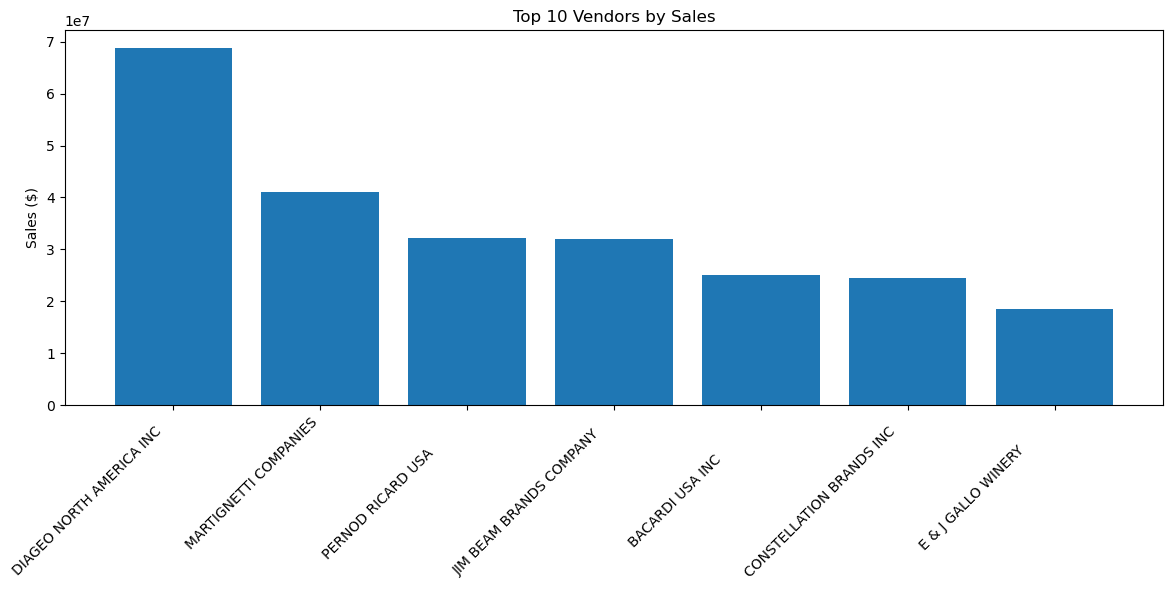

In [67]:
# ============================================================
# TOP 10 VENDORS BY SALES
# ============================================================

top10_sales = (
    vendor_final
    .sort_values('TotalSalesDollars', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.bar(
    top10_sales['VendorName'],
    top10_sales['TotalSalesDollars']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Sales ($)')
plt.title('Top 10 Vendors by Sales')

plt.tight_layout()
plt.show()

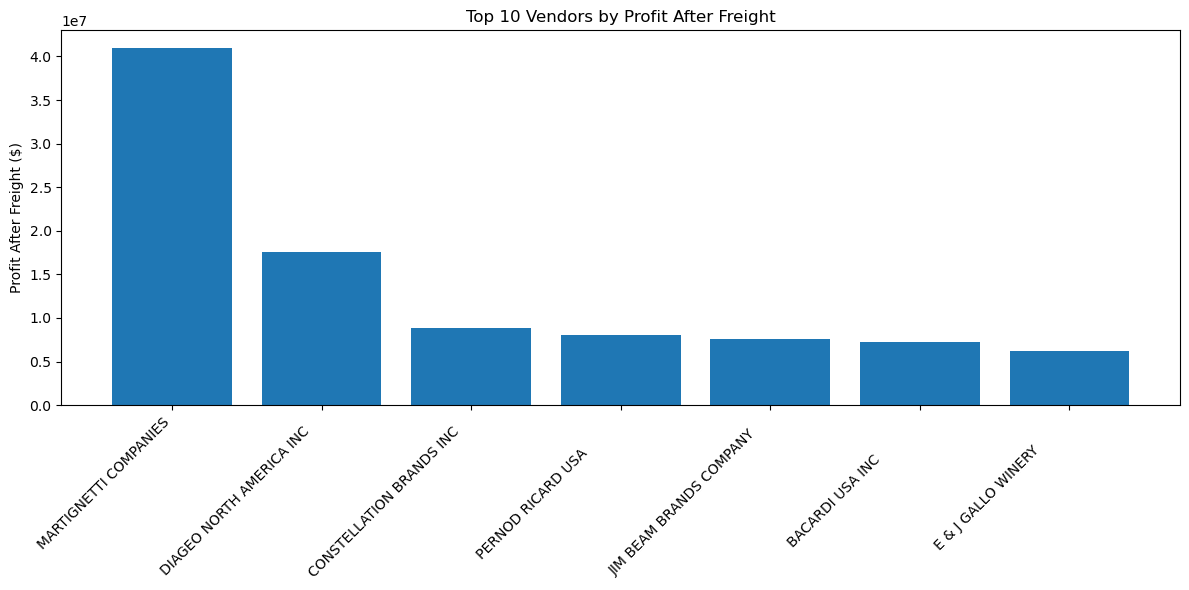

In [68]:
# ============================================================
# TOP 10 VENDORS BY PROFIT
# ============================================================

top10_profit = (
    vendor_final
    .sort_values('ProfitAfterFreight', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.bar(
    top10_profit['VendorName'],
    top10_profit['ProfitAfterFreight']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Profit After Freight ($)')
plt.title('Top 10 Vendors by Profit After Freight')

plt.tight_layout()
plt.show()

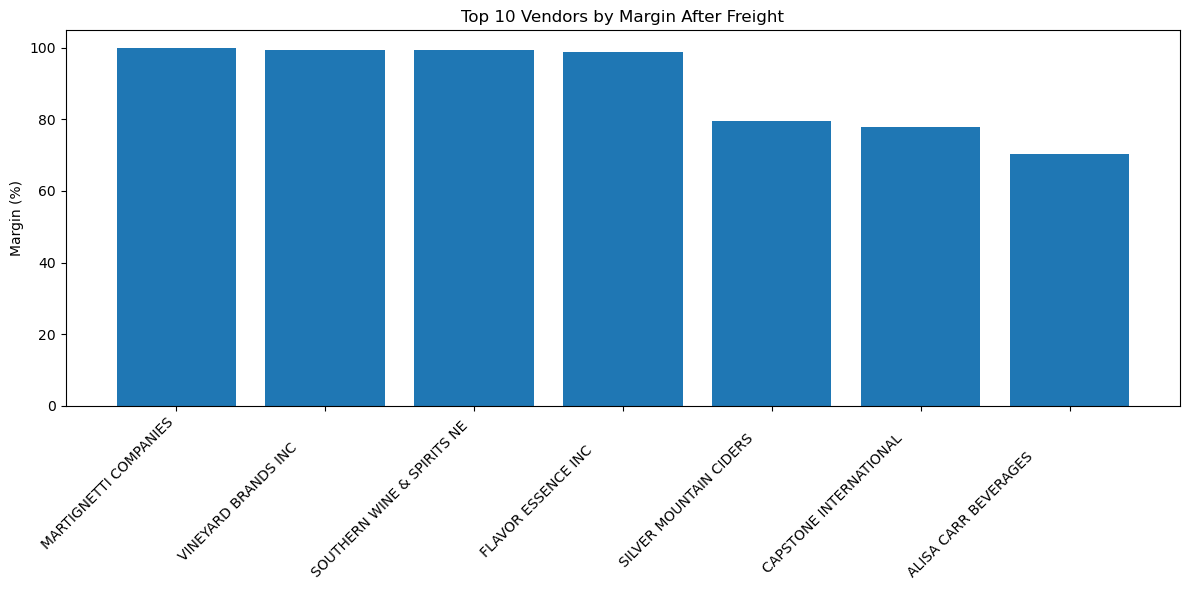

In [69]:
# ============================================================
# TOP 10 VENDORS BY MARGIN
# ============================================================

top10_margin = (
    vendor_final
    .sort_values('MarginAfterFreight', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.bar(
    top10_margin['VendorName'],
    top10_margin['MarginAfterFreight']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Margin (%)')
plt.title('Top 10 Vendors by Margin After Freight')

plt.tight_layout()
plt.show()


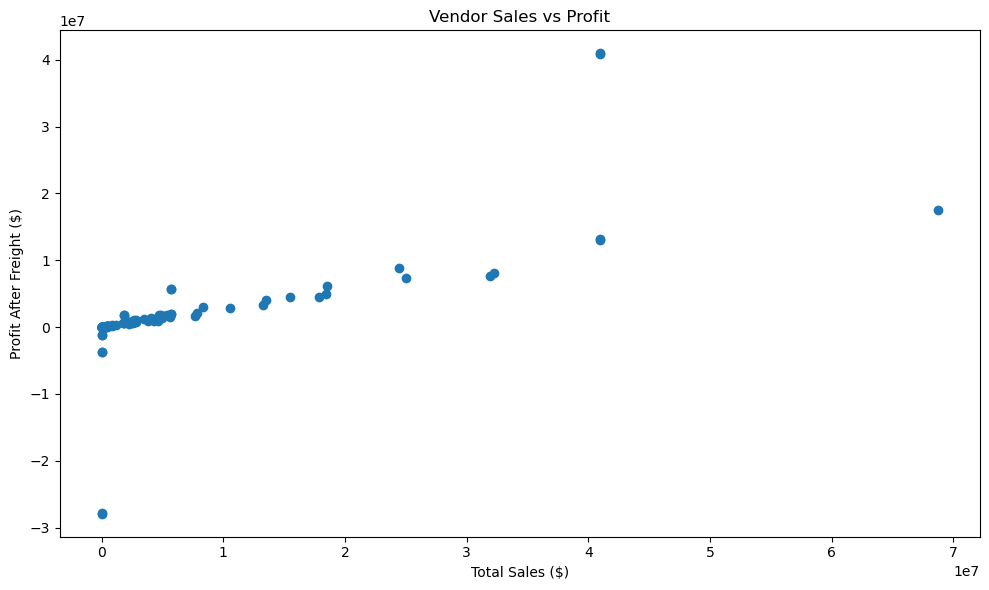

In [70]:
# ============================================================
# SALES VS PROFIT
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    vendor_final['TotalSalesDollars'],
    vendor_final['ProfitAfterFreight']
)

plt.xlabel('Total Sales ($)')
plt.ylabel('Profit After Freight ($)')
plt.title('Vendor Sales vs Profit')

plt.tight_layout()
plt.show()

In [71]:
# ============================================================
# FINAL VENDOR DATASET
# ============================================================

final_vendor_analysis = vendor_final[
    [
        'VendorNo',
        'VendorName',
        'TotalSalesDollars',
        'TotalSalesQuantity',
        'TotalPurchaseDollars',
        'TotalPurchaseQuantity',
        'GrossProfit',
        'ProfitMargin',
        'TotalInvoiceDollars',
        'TotalFreight',
        'TotalInvoiceQuantity',
        'TotalPurchaseOrders',
        'ProfitAfterFreight',
        'MarginAfterFreight',
        'SalesSharePercent',
        'PurchaseSharePercent',
        'FreightPercentOfSales',
        'PerformanceCategory'
    ]
].copy()

print("Final Vendor Dataset:", final_vendor_analysis.shape)

display(final_vendor_analysis.head(20))

Final Vendor Dataset: (148, 18)


,VendorNo,VendorName,TotalSalesDollars,TotalSalesQuantity,TotalPurchaseDollars,TotalPurchaseQuantity,GrossProfit,ProfitMargin,TotalInvoiceDollars,TotalFreight,TotalInvoiceQuantity,TotalPurchaseOrders,ProfitAfterFreight,MarginAfterFreight,SalesSharePercent,PurchaseSharePercent,FreightPercentOfSales,PerformanceCategory
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",1265.58,42,5630.88,328.0,-4365.30,-344.924857,5630.88,27.08,328.0,4.0,-4392.38,-347.064587,0.000212,0.001340,2.139730,Loss / Negative Profit
1,60,ADAMBA IMPORTS INTL INC,67576.22,3978,76770.25,4732.0,-9194.03,-13.605422,76770.25,367.52,4732.0,35.0,-9561.55,-14.149282,0.011299,0.018264,0.543860,Loss / Negative Profit
2,105,ALTAMAR BRANDS LLC,15748.75,325,11706.20,332.0,4042.55,25.669021,11706.20,62.39,332.0,40.0,3980.16,25.272863,0.002633,0.002785,0.396158,High Margin
3,200,AMERICAN SPIRITS EXCHANGE,1719.97,103,1205.16,132.0,514.81,29.931336,1205.16,6.19,132.0,6.0,508.62,29.571446,0.000288,0.000287,0.359890,High Margin
4,287,APPOLO VINEYARDS LLC,1616.92,108,2399.70,230.0,-782.78,-48.411795,2399.70,12.28,230.0,13.0,-795.06,-49.171264,0.000270,0.000571,0.759469,Loss / Negative Profit
5,388,ATLANTIC IMPORTING COMPANY,59272.75,1825,41116.32,1847.0,18156.43,30.632002,41116.32,211.74,1847.0,53.0,17944.69,30.274772,0.009911,0.009782,0.357230,High Margin
6,480,BACARDI USA INC,25014556.89,1457301,17624378.72,1427075.0,7390178.17,29.543510,17624378.72,89286.27,1427075.0,55.0,7300891.90,29.186573,4.182593,4.192998,0.356937,High Margin
7,516,BANFI PRODUCTS CORP,2646325.62,221040,1628866.68,228103.0,1017458.94,38.447987,1628866.68,8510.41,228103.0,55.0,1008948.53,38.126394,0.442482,0.387522,0.321593,High Margin
8,653,STATE WINE & SPIRITS,2299075.40,157700,1529682.04,154092.0,769393.36,33.465338,1529682.04,8014.98,154092.0,55.0,761378.38,33.116721,0.384420,0.363925,0.348618,High Margin
9,660,SAZERAC NORTH AMERICA INC.,4965061.47,493413,3537977.55,503931.0,1427083.92,28.742523,3537977.55,17932.33,503931.0,55.0,1409151.59,28.381352,0.830190,0.841717,0.361170,High Margin


In [72]:
# ============================================================
# PRODUCT PERFORMANCE CATEGORY
# ============================================================

product_analysis['PerformanceCategory'] = np.select(
    [
        (product_analysis['GrossProfit'] > 0) &
        (product_analysis['ProfitMargin'] >= 20),

        (product_analysis['GrossProfit'] > 0) &
        (product_analysis['ProfitMargin'] < 20),

        (product_analysis['GrossProfit'] <= 0)
    ],
    [
        'High Margin',
        'Low Margin',
        'Loss / Negative Profit'
    ],
    default='Unknown'
)

display(
    product_analysis[
        [
            'Brand',
            'Description',
            'VendorName',
            'TotalSalesDollars',
            'GrossProfit',
            'ProfitMargin',
            'PerformanceCategory'
        ]
    ].head(20)
)

,Brand,Description,VendorName,TotalSalesDollars,GrossProfit,ProfitMargin,PerformanceCategory
0,1233,Jack Daniels No 7 Black,BROWN-FORMAN CORP,5101919.51,1290667.91,25.297693,High Margin
1,3405,Tito's Handmade Vodka,MARTIGNETTI COMPANIES,4819073.49,1015032.27,21.062810,High Margin
2,8068,Absolut 80 Proof,PERNOD RICARD USA,4538120.60,1119816.92,24.675786,High Margin
3,4261,Capt Morgan Spiced Rum,DIAGEO NORTH AMERICA INC,4475972.88,1214774.94,27.139908,High Margin
4,3545,Ketel One Vodka,DIAGEO NORTH AMERICA INC,4223107.62,1199901.61,28.412764,High Margin
5,3858,Grey Goose Vodka,BACARDI USA INC,3383912.40,917276.47,27.106980,High Margin
6,2589,Jameson Irish Whiskey,PERNOD RICARD USA,2773367.73,596082.65,21.493098,High Margin
7,3489,Tanqueray,DIAGEO NORTH AMERICA INC,2640491.19,736751.64,27.902068,High Margin
8,3102,Smirnoff Traveler,DIAGEO NORTH AMERICA INC,2592041.35,503706.51,19.432812,Low Margin
9,1376,Jim Beam,JIM BEAM BRANDS COMPANY,2435393.39,661966.25,27.181081,High Margin


In [73]:
# ============================================================
# PRODUCT PERFORMANCE SUMMARY
# ============================================================

product_category_summary = (
    product_analysis
    .groupby('PerformanceCategory', as_index=False)
    .agg(
        ProductCount=('Brand', 'count'),
        TotalSales=('TotalSalesDollars', 'sum'),
        TotalProfit=('GrossProfit', 'sum')
    )
)

display(product_category_summary)

,PerformanceCategory,ProductCount,TotalSales,TotalProfit
0,High Margin,8250,3.976366e+08,1.276136e+08
1,Loss / Negative Profit,1950,1.022466e+07,-4.073878e+06
2,Low Margin,1077,4.420170e+07,6.926915e+06


In [74]:
# ============================================================
# TOP PRODUCTS BY PROFIT
# ============================================================

top_products_profit = (
    product_analysis
    .sort_values('GrossProfit', ascending=False)
    .head(20)
)

display(
    top_products_profit[
        [
            'Brand',
            'Description',
            'Size',
            'VendorName',
            'TotalSalesQuantity',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'GrossProfit',
            'ProfitMargin'
        ]
    ]
)

,Brand,Description,Size,VendorName,TotalSalesQuantity,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
0,1233,Jack Daniels No 7 Black,1.75L,BROWN-FORMAN CORP,142049,5101919.51,3811251.60,1290667.91,25.297693
3,4261,Capt Morgan Spiced Rum,1.75L,DIAGEO NORTH AMERICA INC,200412,4475972.88,3261197.94,1214774.94,27.139908
4,3545,Ketel One Vodka,1.75L,DIAGEO NORTH AMERICA INC,135838,4223107.62,3023206.01,1199901.61,28.412764
2,8068,Absolut 80 Proof,1.75L,PERNOD RICARD USA,187140,4538120.60,3418303.68,1119816.92,24.675786
1,3405,Tito's Handmade Vodka,1.75L,MARTIGNETTI COMPANIES,160247,4819073.49,3804041.22,1015032.27,21.062810
5,3858,Grey Goose Vodka,750mL,BACARDI USA INC,141860,3383912.40,2466635.93,917276.47,27.106980
10,6570,Kendall Jackson Chard Vt RSV,750mL,MAJESTIC FINE WINES,214238,2326007.78,1460072.36,865935.42,37.228397
7,3489,Tanqueray,1.75L,DIAGEO NORTH AMERICA INC,90481,2640491.19,1903739.55,736751.64,27.902068
11,2663,Dewars White Label,1.75L,BACARDI USA INC,70122,2189368.78,1478001.42,711367.36,32.491893
13,8082,Baileys Irish Cream,1.75L,DIAGEO NORTH AMERICA INC,65184,2068091.16,1396130.77,671960.39,32.491817


In [75]:
# ============================================================
# LOSS-MAKING PRODUCTS
# ============================================================

loss_products = (
    product_analysis[
        product_analysis['GrossProfit'] <= 0
    ]
    .sort_values('GrossProfit')
)

print("Loss-making products:", len(loss_products))

display(
    loss_products[
        [
            'Brand',
            'Description',
            'VendorName',
            'TotalSalesDollars',
            'TotalPurchaseDollars',
            'GrossProfit',
            'ProfitMargin'
        ]
    ].head(20)
)

Loss-making products: 1950


,Brand,Description,VendorName,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,ProfitMargin
3195,2277,Kilbeggan Irish Whiskey,JIM BEAM BRANDS COMPANY,20272.54,72275.32,-52002.78,-256.518325
3115,4785,Remy Martin XO Excellence,REMY COINTREAU USA INC,21237.26,59398.95,-38161.69,-179.692154
4162,2289,Whistle Pig Boss Hog Rye,PERFECTA WINES,11062.63,44489.34,-33426.71,-302.158799
6339,5609,Integre Vodka,M S WALKER INC,2575.70,33560.28,-30984.58,-1202.957643
3961,3365,Russian Standard Vodka,Russian Standard Vodka,12569.97,41850.60,-29280.63,-232.941129
5114,6904,Westland Trinity 3 Pack,ULTRA BEVERAGE COMPANY LLP,6149.18,35300.16,-29150.98,-474.062883
10078,15880,San Polo Brun di Montlcno 11,SOUTHERN WINE & SPIRITS NE,149.98,29214.00,-29064.02,-19378.597146
1703,25588,High Valley Znfdl,SOUTHERN WINE & SPIRITS NE,55406.43,80209.34,-24802.91,-44.765400
1918,13530,Home Ranch Sbragia Chard,MARTIGNETTI COMPANIES,47958.40,72486.61,-24528.21,-51.144763
6336,2204,Bowmore 25 Yr Single Malt,JIM BEAM BRANDS COMPANY,2579.94,27073.35,-24493.41,-949.379055


# Descriptive statistics

In [90]:
vendor_numeric_cols = [
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'GrossProfit',
    'ProfitMargin',
    'TotalFreight',
    'ProfitAfterFreight',
    'MarginAfterFreight'
]

vendor_statistics = final_vendor_analysis[vendor_numeric_cols].describe().T

vendor_statistics

vendor_stat_summary = pd.DataFrame({
    'Mean': final_vendor_analysis[vendor_numeric_cols].mean(),
    'Median': final_vendor_analysis[vendor_numeric_cols].median(),
    'Std_Dev': final_vendor_analysis[vendor_numeric_cols].std(),
    'Minimum': final_vendor_analysis[vendor_numeric_cols].min(),
    'Maximum': final_vendor_analysis[vendor_numeric_cols].max()
})

vendor_stat_summary

ewness = final_vendor_analysis[vendor_numeric_cols].skew()

skewness.sort_values(ascending=False)

correlation_cols = [
    'TotalSalesDollars',
    'TotalPurchaseDollars',
    'GrossProfit',
    'TotalFreight',
    'ProfitAfterFreight'
]

correlation_matrix = final_vendor_analysis[
    correlation_cols
].corr()

correlation_matrix


,TotalSalesDollars,TotalPurchaseDollars,GrossProfit,TotalFreight,ProfitAfterFreight
TotalSalesDollars,1.000000,0.774995,0.707676,0.772767,0.704615
TotalPurchaseDollars,0.774995,1.000000,0.101937,0.783315,0.097640
GrossProfit,0.707676,0.101937,1.000000,0.339474,0.999985
TotalFreight,0.772767,0.783315,0.339474,1.000000,0.334393
ProfitAfterFreight,0.704615,0.097640,0.999985,0.334393,1.000000


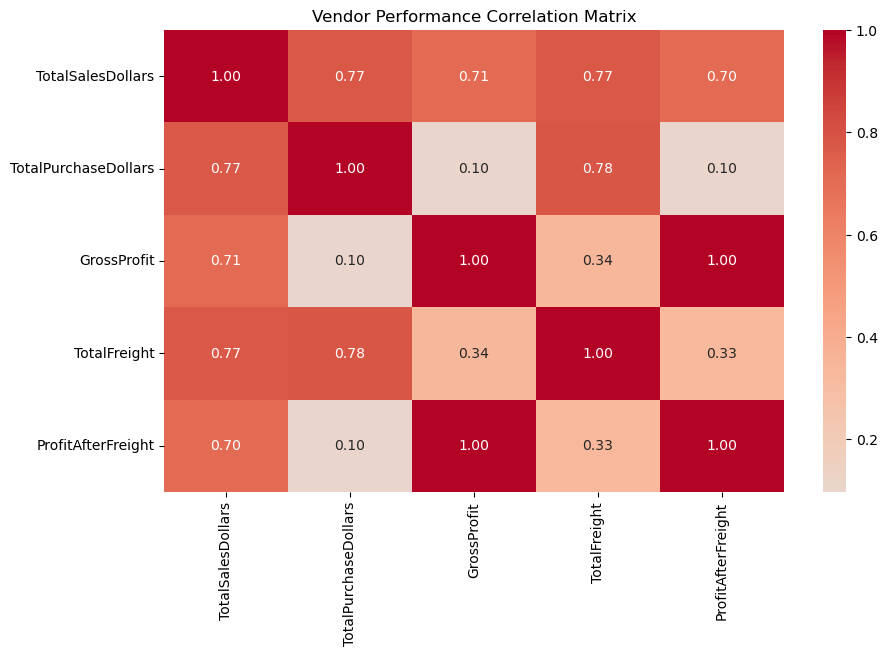

In [80]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Vendor Performance Correlation Matrix')
plt.show()

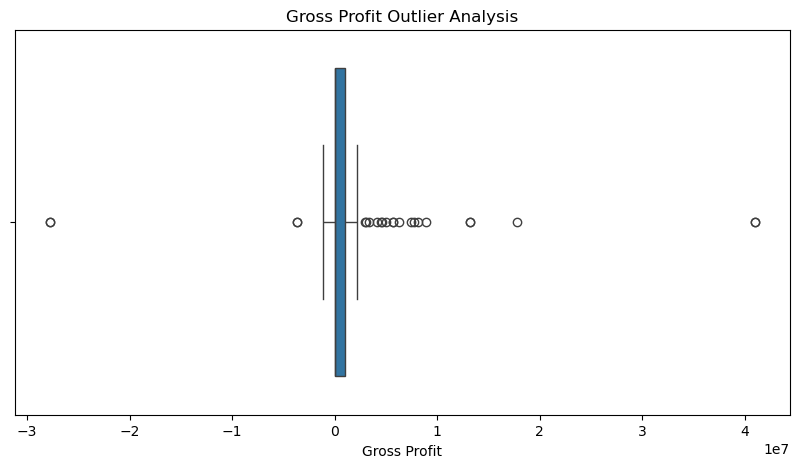

In [81]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=final_vendor_analysis['GrossProfit']
)

plt.title('Gross Profit Outlier Analysis')
plt.xlabel('Gross Profit')

plt.show()

In [82]:
Q1 = final_vendor_analysis['GrossProfit'].quantile(0.25)
Q3 = final_vendor_analysis['GrossProfit'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = final_vendor_analysis[
    (final_vendor_analysis['GrossProfit'] < lower_bound) |
    (final_vendor_analysis['GrossProfit'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 2191.5699999999997
Q3: 997368.8799999994
IQR: 995177.3099999995
Lower Bound: -1490574.394999999
Upper Bound: 2490134.844999999
Number of Outliers: 23


In [83]:
outliers[
    ['VendorName', 'TotalSalesDollars', 'GrossProfit', 'ProfitMargin']
].sort_values(
    'GrossProfit',
    ascending=False
).head(10)

,VendorName,TotalSalesDollars,GrossProfit,ProfitMargin
58,MARTIGNETTI COMPANIES,40992395.93,40952179.82,99.901894
59,MARTIGNETTI COMPANIES,40992395.93,40952179.82,99.901894
54,DIAGEO NORTH AMERICA INC,68742416.99,17782620.14,25.868483
57,MARTIGNETTI COMPANIES,40992395.93,13170922.02,32.130159
56,MARTIGNETTI COMPANIES,40992395.93,13170922.02,32.130159
16,CONSTELLATION BRANDS INC,24469172.93,8895255.03,36.352904
120,PERNOD RICARD USA,32281247.95,8157156.39,25.269024
116,JIM BEAM BRANDS COMPANY,31906320.54,7703169.49,24.143083
6,BACARDI USA INC,25014556.89,7390178.17,29.543510
48,E & J GALLO WINERY,18556085.61,6266477.52,33.770471


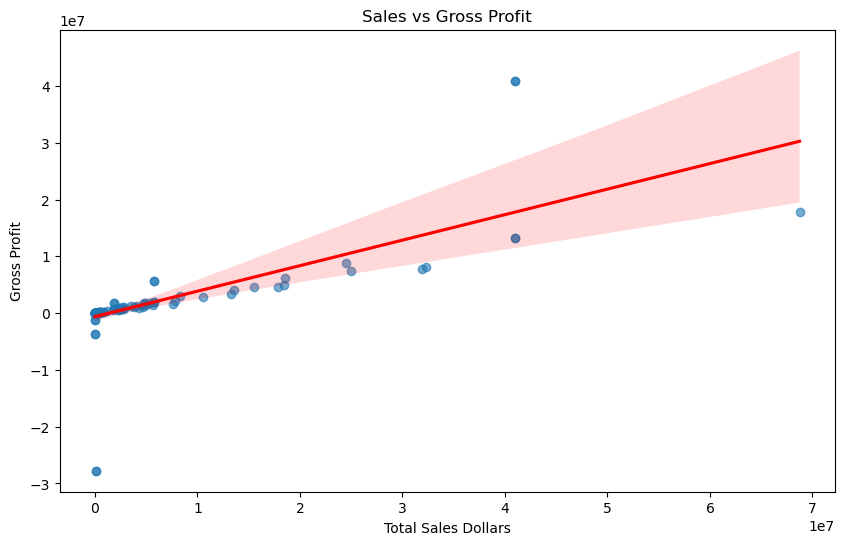

In [86]:
#Sales vs Gross Profit Visualization
plt.figure(figsize=(10, 6))

sns.regplot(
    data=final_vendor_analysis,
    x='TotalSalesDollars',
    y='GrossProfit',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Sales vs Gross Profit')
plt.xlabel('Total Sales Dollars')
plt.ylabel('Gross Profit')

plt.show()

In [67]:
# ============================================================
# FINAL PRODUCT ANALYSIS DATASET
# ============================================================

final_product_analysis = product_analysis[
    [
        'Brand',
        'Description',
        'Size',
        'VendorNo',
        'VendorName',
        'TotalSalesQuantity',
        'TotalSalesDollars',
        'AverageSalesPrice',
        'TotalPurchaseQuantity',
        'TotalPurchaseDollars',
        'AveragePurchasePrice',
        'GrossProfit',
        'ProfitMargin',
        'PriceDifference',
        'ProductMarginPercent',
        'PerformanceCategory'
    ]
].copy()

print("Final Product Dataset Shape:",
      final_product_analysis.shape)

display(final_product_analysis.head(20))

Final Product Dataset Shape: (11277, 16)


,Brand,Description,Size,VendorNo,VendorName,TotalSalesQuantity,TotalSalesDollars,AverageSalesPrice,TotalPurchaseQuantity,TotalPurchaseDollars,AveragePurchasePrice,GrossProfit,ProfitMargin,PriceDifference,ProductMarginPercent,PerformanceCategory
0,1233,Jack Daniels No 7 Black,1.75L,1128,BROWN-FORMAN CORP,142049,5101919.51,36.233470,145080.0,3811251.60,26.27,1290667.91,25.297693,9.963470,27.497974,High Margin
1,3405,Tito's Handmade Vodka,1.75L,4425,MARTIGNETTI COMPANIES,160247,4819073.49,30.314332,164038.0,3804041.22,23.19,1015032.27,21.062810,7.124332,23.501530,High Margin
2,8068,Absolut 80 Proof,1.75L,17035,PERNOD RICARD USA,187140,4538120.60,24.483151,187407.0,3418303.68,18.24,1119816.92,24.675786,6.243151,25.499786,High Margin
3,4261,Capt Morgan Spiced Rum,1.75L,3960,DIAGEO NORTH AMERICA INC,200412,4475972.88,22.830046,201682.0,3261197.94,16.17,1214774.94,27.139908,6.660046,29.172284,High Margin
4,3545,Ketel One Vodka,1.75L,3960,DIAGEO NORTH AMERICA INC,135838,4223107.62,31.417124,138109.0,3023206.01,21.89,1199901.61,28.412764,9.527124,30.324622,High Margin
5,3858,Grey Goose Vodka,750mL,480,BACARDI USA INC,141860,3383912.40,24.568858,138809.0,2466635.93,17.77,917276.47,27.106980,6.798858,27.672665,High Margin
6,2589,Jameson Irish Whiskey,1.75L,17035,PERNOD RICARD USA,69627,2773367.73,40.520199,70783.0,2177285.08,30.76,596082.65,21.493098,9.760199,24.087244,High Margin
7,3489,Tanqueray,1.75L,3960,DIAGEO NORTH AMERICA INC,90481,2640491.19,29.457306,91835.0,1903739.55,20.73,736751.64,27.902068,8.727306,29.626966,High Margin
8,3102,Smirnoff Traveler,1.75L,3960,DIAGEO NORTH AMERICA INC,148265,2592041.35,17.656526,161386.0,2088334.84,12.94,503706.51,19.432812,4.716526,26.712649,Low Margin
9,1376,Jim Beam,1.75L,12546,JIM BEAM BRANDS COMPANY,107061,2435393.39,23.048417,108866.0,1773427.14,16.29,661966.25,27.181081,6.758417,29.322695,High Margin


In [68]:
# ============================================================
# SAVE FINAL ANALYSIS TABLES
# ============================================================

output_folder = r"C:\Users\rishu\Downloads\data\data\final_analysis"

os.makedirs(output_folder, exist_ok=True)

final_vendor_analysis.to_csv(
    os.path.join(output_folder, "final_vendor_analysis.csv"),
    index=False
)

final_product_analysis.to_csv(
    os.path.join(output_folder, "final_product_analysis.csv"),
    index=False
)

inventory_change.to_csv(
    os.path.join(output_folder, "inventory_analysis.csv"),
    index=False
)

category_summary.to_csv(
    os.path.join(output_folder, "vendor_category_summary.csv"),
    index=False
)

product_category_summary.to_csv(
    os.path.join(output_folder, "product_category_summary.csv"),
    index=False
)

print("All final analysis files saved successfully!")
print("Folder:", output_folder)

All final analysis files saved successfully!
Folder: C:\Users\rishu\Downloads\data\data\final_analysis


In [69]:
# ============================================================
# VERIFY OUTPUT FILES
# ============================================================

for file in os.listdir(output_folder):
    print(file)

final_product_analysis.csv
final_vendor_analysis.csv
inventory_analysis.csv
product_category_summary.csv
vendor_category_summary.csv
